# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [ ]:
#Installing the libraries with the specified versions
!pip install "numpy>=2.0.2" "pandas>=2.2.2" scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 huggingface_hub==0.34.0

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

# **Loading the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
kart = pd.read_csv("/content/drive/MyDrive/Great Learning/Project 7 SuperKart/SuperKart.csv")

In [ ]:
# copying data to another variable to avoid any changes to original data
data = kart.copy()

# **Data Overview**

In [ ]:
# Display the first five rows of the dataset
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [ ]:
#Display the last 5 rows
data.tail()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
8758,NC7546,14.80,No Sugar,0.016,Health and Hygiene,140.53,OUT004,2009,Medium,Tier 2,Supermarket Type2,3806.53
8759,NC584,14.06,No Sugar,0.142,Household,144.51,OUT004,2009,Medium,Tier 2,Supermarket Type2,5020.74
8760,NC2471,13.48,No Sugar,0.017,Health and Hygiene,88.58,OUT001,1987,High,Tier 2,Supermarket Type1,2443.42
8761,NC7187,13.89,No Sugar,0.193,Household,168.44,OUT001,1987,High,Tier 2,Supermarket Type1,4171.82
8762,FD306,14.73,Low Sugar,0.177,Snack Foods,224.93,OUT002,1998,Small,Tier 3,Food Mart,2186.08


In [ ]:
# Checking shape of the data
print(f"There are {data.shape[0]} rows and {data.shape[1]} columns.")

There are 8763 rows and 12 columns.


In [ ]:
#Checking the datatypes and columns
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


Observations:
- Every single column reports exactly 8,763 non-null entries,indicating there are no missing values.
- Product_Weight, Product_Allocated_Area, Product_MRP, Store_Establishment_Year and Product_Store_Sales_Total are all numerical in nature.
- The rest of the columns are categorical-type variables.


In [ ]:
#Statistical summary of the data
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Observations:
- The sales values range from 33.0 to 8,000.0, with a mean of aproximately 3,464.00 and a median (50%) of 3,452.34.
- The proximity of the mean and median indicates an overall balanced central tendency, though the maximum value of 8,000 indicates a slight right-hand tail of high-performing sales items that warrants an outlier check.
- Prices of products span between 31.0 and 266.0, centering around a mean of around 147.03 and a median of 146.74.
- The distribution of the Product Alloted Area variable is right-skewed, as the 75th percentile is 0.096 while the maximum reaches nearly 0.30.
- Weights range from 4.0 to 22.0, with a mean of approximately 12.65 and a median of 12.66, showing a symmetric distribution.
- Stores in this dataset were founded between 1987 and 2009. Over 50% of the records correspond to stores established in 2009 (both 50% and 75% quartiles are at 2009).
- The data dictionary specifies three classes for the Product Sugar Content varialbe (low sugar, regular, no sugar), but the summary reveals 4 unique categories. This needs to be checked.
- "Low Sugar" is the predominant category, occurring 4,885 times.
- There are only 4 unique stores in the entire dataset. Store OUT004 accounts for more than half of the data. Similarly, Supermarket Type2 is also the most frequent type of store, which means that the OUT004 store is a type 2 supermarket.
- Medium stores dominate the dataset.
- Tier 2 cities comprise the vast majority of entries.
- There are 16 unique product types, with Fruits and Vegetables being the most frequent category.

In [ ]:
# checking for duplicate values
data.duplicated().sum()

np.int64(0)

Observations:
- There are no duplicated values in this dataset.

In [ ]:
# checking for missing values in the data
data.isnull().sum()

,0
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


Observations:
- There are no missing values in this dataset.

In [ ]:
# Seeing the unique values and the frequency of each category in Product_Sugar_Content
data['Product_Sugar_Content'].value_counts()

,count
Product_Sugar_Content,
Low Sugar,4885
Regular,2251
No Sugar,1519
reg,108


In [ ]:
# Standardizing 'reg' to 'Regular'
data['Product_Sugar_Content'] = data['Product_Sugar_Content'].replace({'reg': 'Regular'})

In [ ]:
# Verifying the cleaned categories
data['Product_Sugar_Content'].value_counts()

,count
Product_Sugar_Content,
Low Sugar,4885
Regular,2359
No Sugar,1519


# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

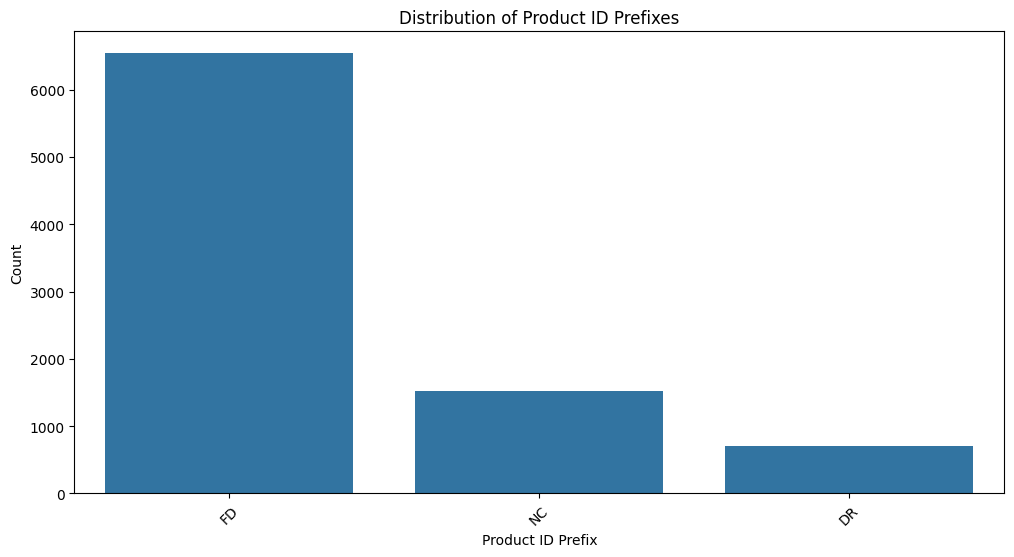

In [ ]:
#For Prduct_ID
# Extract the first two letters from Product_Id
data['Product_Id_Prefix'] = data['Product_Id'].str[:2]

# Count how many observations belong to each product prefix
plt.figure(figsize=(12, 6))
sns.countplot(
    data=data,
    x='Product_Id_Prefix',
    order=data['Product_Id_Prefix'].value_counts().index
)

plt.title('Distribution of Product ID Prefixes')
plt.xlabel('Product ID Prefix')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Observations:
- Product_Id functions as a unique identifier rather than a numerical variable, so its analysis focuses on the patterns found within the ID values.
- The product IDs can be grouped into three prefixes: FD, NC, and DR.
- FD is the most common prefix, appearing in approximately 6,500 records. NC follows with around 1,500 records, while DR is the least common with roughly 700 records.
- This indicates that the three prefixes are not evenly represented, with FD accounting for the majority of products in the dataset.
- Although these prefixes may correspond to different product groups, their exact meanings should be verified using the dataset documentation before interpreting them as specific categories.

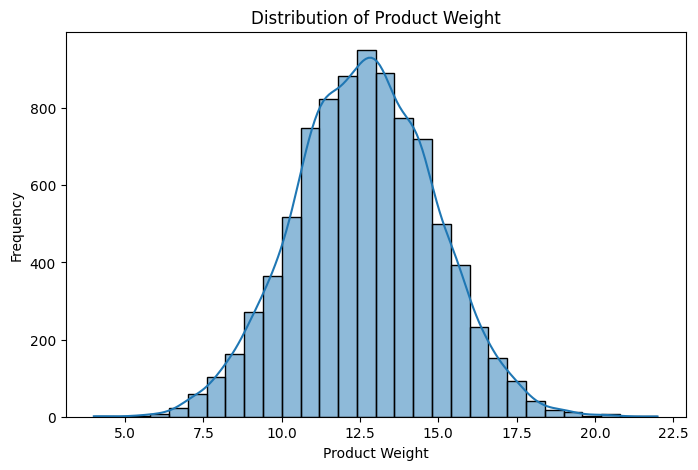

In [ ]:
#For Product_Weight:
# Shows the distribution of product weights
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='Product_Weight', bins=30, kde=True)

plt.title('Distribution of Product Weight')
plt.xlabel('Product Weight')
plt.ylabel('Frequency')
plt.show()

Observations:
- The distribution of Product_Weight is approximately bell-shaped and symmetric.
- Most product weights are concentrated around 12 to 14.
- The highest frequency occurs close to a weight of about 13.
- Very low weights, below roughly 7, are uncommon.
- Very high weights, above roughly 19, are also uncommon.
- There does not appear to be strong positive or negative skewness.

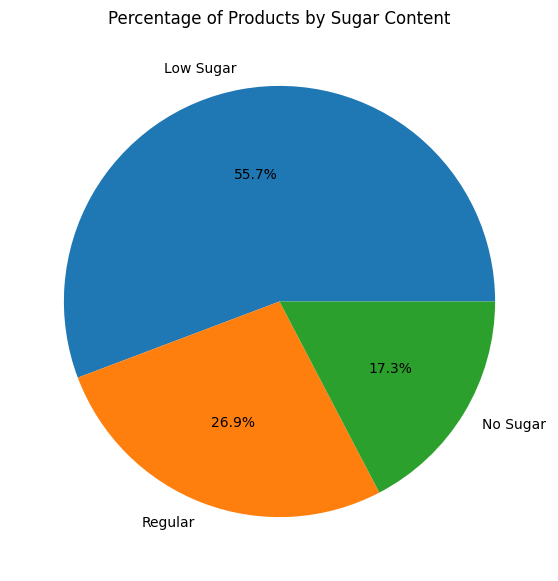

In [ ]:
#For Product_Sugar_Content:
# Calculate the number of observations in each sugar-content category
sugar_counts = data['Product_Sugar_Content'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    sugar_counts.values,
    labels=sugar_counts.index,
    autopct='%1.1f%%'
)

plt.title('Percentage of Products by Sugar Content')
plt.show()

Observations:
- Low Sugar represents 55.7% of all observations.
- Regular products represent 26.9% of the dataset.
- No Sugar products represent 17.3% of the dataset.
- More than half of the products in the dataset are classified as Low Sugar.
- Low Sugar alone accounts for a larger share than Regular and No Sugar individually by a wide margin.
- The dataset is strongly concentrated toward products labeled as Low Sugar.

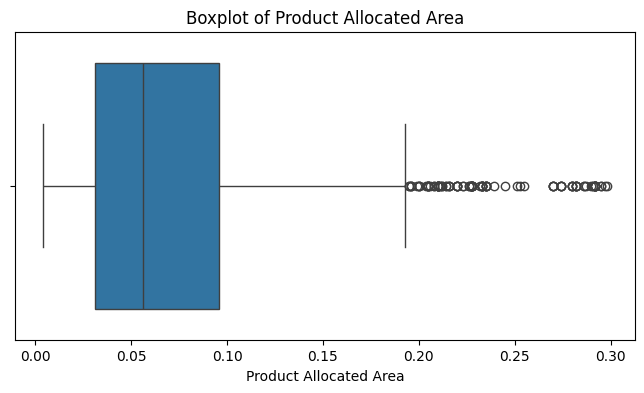

In [ ]:
#For Product_Allocated_Area:
# Helps identify the median, spread and possible unusual values
plt.figure(figsize=(8, 4))
sns.boxplot(data=data, x='Product_Allocated_Area')

plt.title('Boxplot of Product Allocated Area')
plt.xlabel('Product Allocated Area')
plt.show()

Observations:
- The median allocated area is approximately 0.055.
- The lower quartile appears to be around 0.03.
- The upper quartile appears to be around 0.09.
- Therefore, the middle 50% of observations are concentrated roughly between 0.03 and 0.09.
- The median is closer to the lower side of the box than would be expected in a perfectly symmetric distribution.
- The upper whisker extends much farther than the lower whisker, reaching approximately 0.19.
- This asymmetry confirms a positive or right skewness.
- There are many observations above the upper whisker, beginning around 0.19–0.20. These observations are identified by the boxplot as potential high-end outliers.
- Some extreme values approach approximately 0.30.
- There do not appear to be comparable low-end outliers.

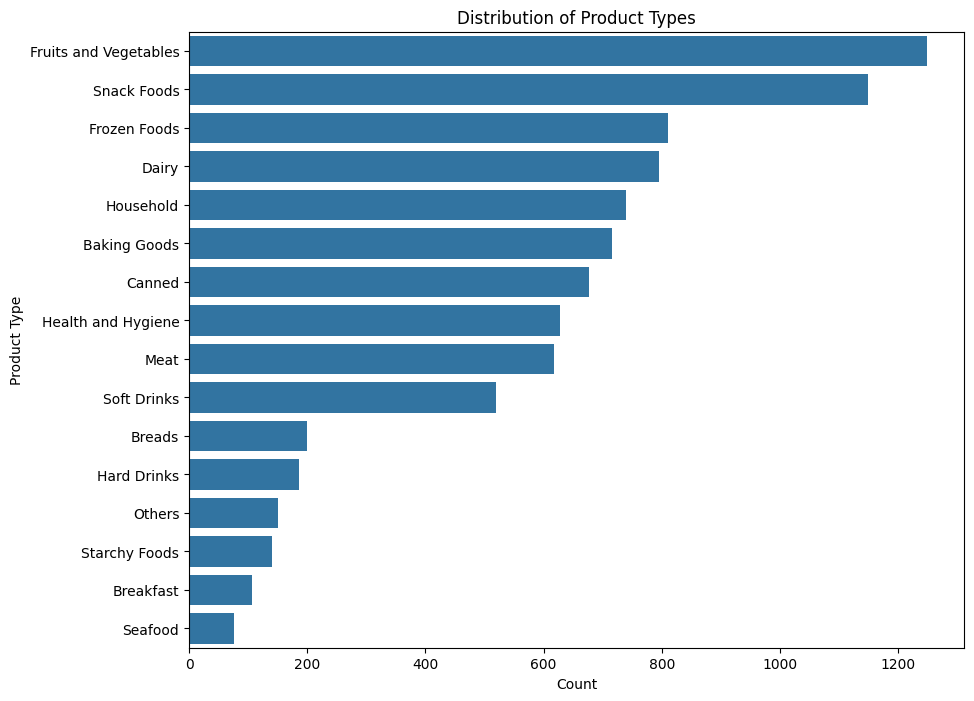

In [ ]:
#For Product_Type:
# Order product categories from most common to least common
product_type_order = data['Product_Type'].value_counts().index

plt.figure(figsize=(10, 8))
sns.countplot(
    data=data,
    y='Product_Type',
    order=product_type_order
)

plt.title('Distribution of Product Types')
plt.xlabel('Count')
plt.ylabel('Product Type')
plt.show()

Observations:
- Fruits and Vegetables is the most frequent product category, with approximately 1,250 observations.
- Snack Foods is the second most frequent category, with roughly 1,150 observations.
- Frozen Foods and Dairy are also common, with approximately 800 observations each.
- Household, Baking Goods, and Canned products form another relatively well-represented group, with approximately 680–750 observations each.
- Health and Hygiene and Meat have similar frequencies, with a little over 600 observations each.
- Soft Drinks appears less frequently, with approximately 520 observations.
- There is a noticeable drop in frequency after Soft Drinks.
- Breads and Hard Drinks each have only around 180–200 observations.
- Others, Starchy Foods, and Breakfast are among the least represented categories.
- Seafood is clearly the least frequent product type, with fewer than 100 observations.
- The number of observations varies considerably across product types, so the categories are not evenly represented.
- The graph shows that the dataset contains a broad variety of product types, but a few categories contribute a much larger number of records than others.

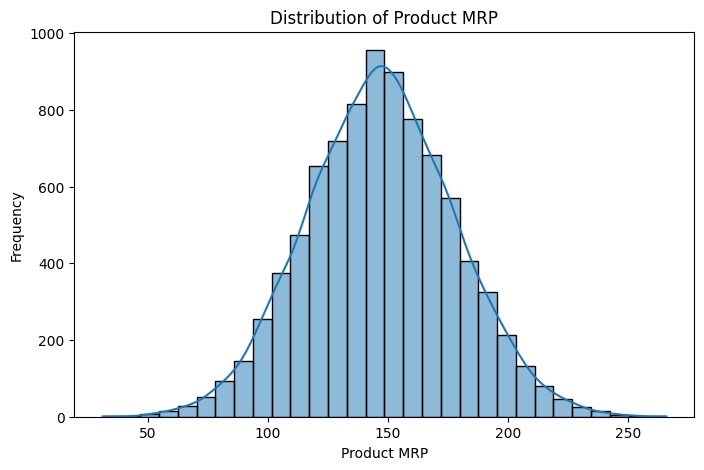

In [ ]:
#For Product_MRP:
# Shows the distribution of maximum retail prices
plt.figure(figsize=(8, 5))
sns.histplot(
    data=data,
    x='Product_MRP',
    bins=30,
    kde=True
)

plt.title('Distribution of Product MRP')
plt.xlabel('Product MRP')
plt.ylabel('Frequency')
plt.show()

Observations:
- The distribution of Product_MRP is approximately bell-shaped and symmetric.
- The highest concentration of observations is around an MRP of approximately 145–155.
- Most products appear to have an MRP between roughly 100 and 200.
- The frequency gradually decreases as the MRP moves away from the center in either direction.
- Very low MRP values, below approximately 60–70, are relatively uncommon.
- Very high MRP values, above approximately 230–240, are also relatively uncommon.
- The KDE curve follows the histogram closely and suggests an approximately normal distribution.
- There does not appear to be substantial positive or negative skewness.
- The overall range appears to extend from roughly 30 to 270.
- The distribution has one clear central peak, so it appears to be unimodal.
- Most products fall within a moderate price range, while products with extremely low or high MRP values are comparatively rare.

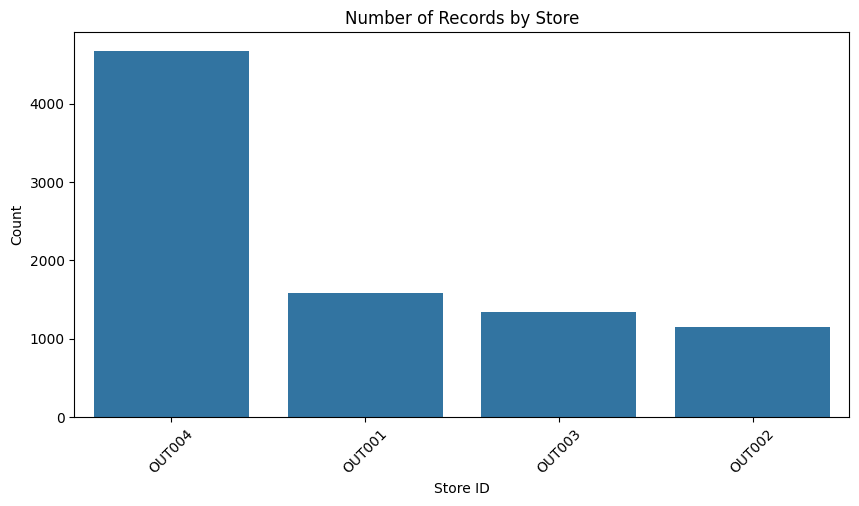

In [ ]:
#For Store_ID:
# Shows how many dataset records correspond to each store
plt.figure(figsize=(10, 5))
sns.countplot(
    data=data,
    x='Store_Id',
    order=data['Store_Id'].value_counts().index
)

plt.title('Number of Records by Store')
plt.xlabel('Store ID')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Observations:
- There are four stores represented in the dataset: OUT004, OUT001, OUT003, and OUT002.
- OUT004 has by far the largest number of records, with roughly 4,600–4,700 observations.
- OUT001 is the second most represented store, with around 1,600 observations.
- OUT003 follows with approximately 1,350 observations.
- OUT002 has the fewest records, with roughly 1,150 observations.
- The distribution of records across stores is therefore highly unbalanced.
- OUT004 has considerably more records than any other store.
- OUT004 has roughly three times as many records as OUT001.
- The other three stores are much closer to each other in terms of record count.
- Since Store_Id is an identifier, this graph does not indicate store performance by itself, it only shows how many dataset observations are associated with each store.

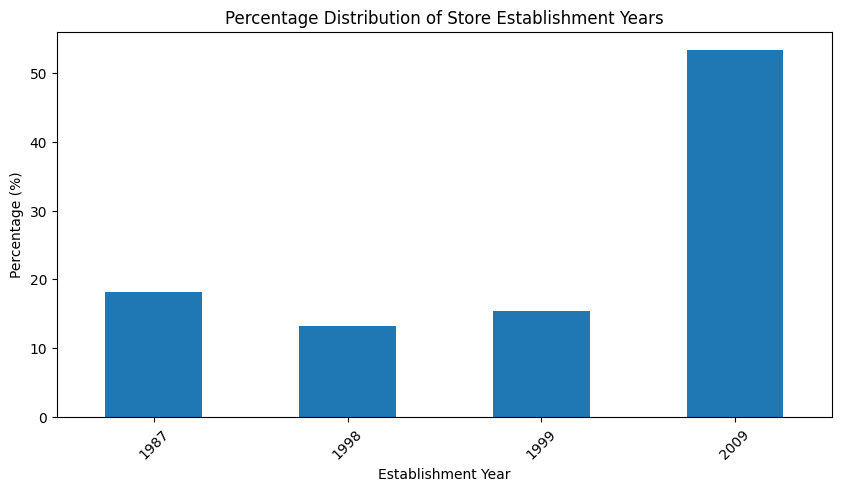

In [ ]:
#For Store_Establishment_Year:
# Calculate the percentage of observations for each establishment year
year_percent = (
    data['Store_Establishment_Year']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

plt.figure(figsize=(10, 5))
year_percent.plot(kind='bar')

plt.title('Percentage Distribution of Store Establishment Years')
plt.xlabel('Establishment Year')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.show()

Observations:
- Stores established in 2009 represent approximately 53% of all observations.
- This means that more than half of the dataset records are associated with stores established in 2009.
- Stores established in 1987 account for about 18% of the observations.
- Stores established in 1999 account for around 15–16%.
- Stores established in 1998 account for approximately 13%, making this the smallest group.
- The percentage distribution confirms that 2009 is the dominant establishment year in the dataset.
- The three earlier years combined represent roughly 47% of the observations.
- Therefore, 2009 alone contributes slightly more observations than the other three establishment years combined.
- The gap between 2009 and the other years is much larger than the differences among 1987, 1998, and 1999.

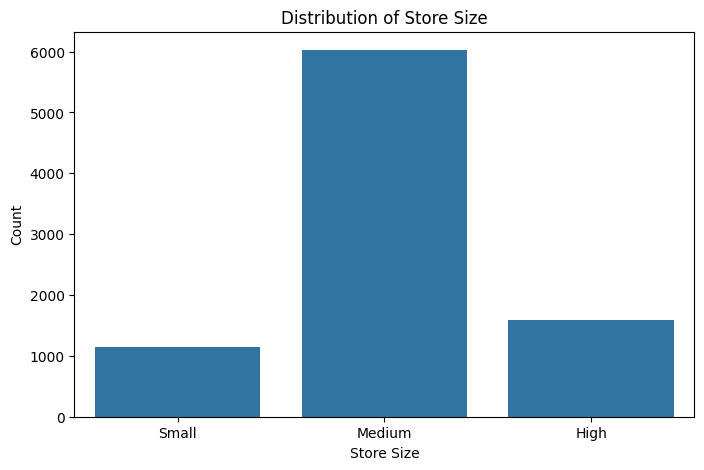

In [ ]:
#For Store_Size:
# Define a logical order for store sizes
size_order = ['Small', 'Medium', 'High']

plt.figure(figsize=(8, 5))
sns.countplot(
    data=data,
    x='Store_Size',
    order=size_order
)

plt.title('Distribution of Store Size')
plt.xlabel('Store Size')
plt.ylabel('Count')
plt.show()

Observations:
- Medium is by far the most common store size in the dataset.
- Medium-sized stores account for roughly 6,000 observations.
- High is the second most represented category, with around 1,600 observations.
- Small is the least represented category, with roughly 1,100–1,200 observations.
- The distribution is therefore highly unbalanced across store sizes.
- Medium-sized stores appear several times more frequently than either small or high stores.
- The difference between Small and High is much smaller than the difference between either of them and Medium.
- The dataset is strongly concentrated in the Medium store-size category.

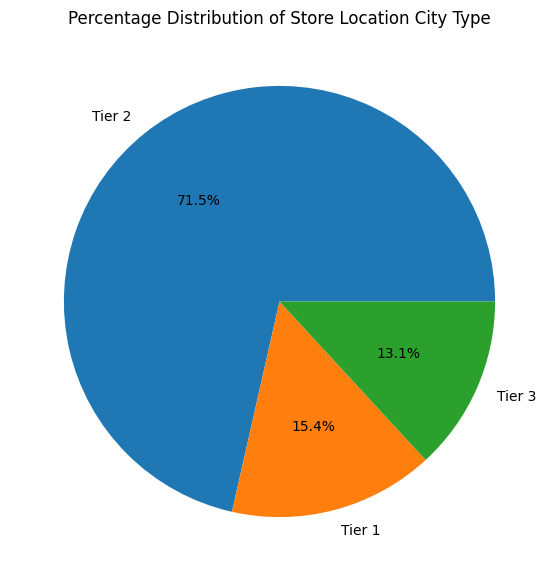

In [ ]:
#For Store_Location_City_Type:
# Count observations belonging to each city tier
tier_counts = data['Store_Location_City_Type'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    tier_counts.values,
    labels=tier_counts.index,
    autopct='%1.1f%%'
)

plt.title('Percentage Distribution of Store Location City Type')
plt.show()

Observations:
- Tier 2 represents 71.5% of all observations.
- This means that more than seven out of every ten records are associated with stores located in Tier 2 cities.
- Tier 1 represents 15.4% of the observations.
- Tier 3 represents 13.1%, making it the least represented city type.
- Tier 1 and Tier 3 together account for only 28.5% of the dataset.
- Tier 2 alone represents more than twice the combined proportion of Tier 1 and Tier 3.
- The difference between Tier 1 and Tier 3 is relatively small, only about 2.3 percentage points.
- The percentage distribution confirms the strong dominance of Tier 2 already visible in the count plot.
- Because Tier 2 makes up such a large proportion of the dataset, overall patterns could be influenced strongly by observations from Tier 2 locations.
- According to the data dictionary, Tier 1 corresponds to cities with a relatively higher standard of living, followed by Tier 2 and Tier 3.
- The graph, however, only illustrates how frequently each city tier appears in the dataset. It does not provide information about sales levels or economic performance for each tier.

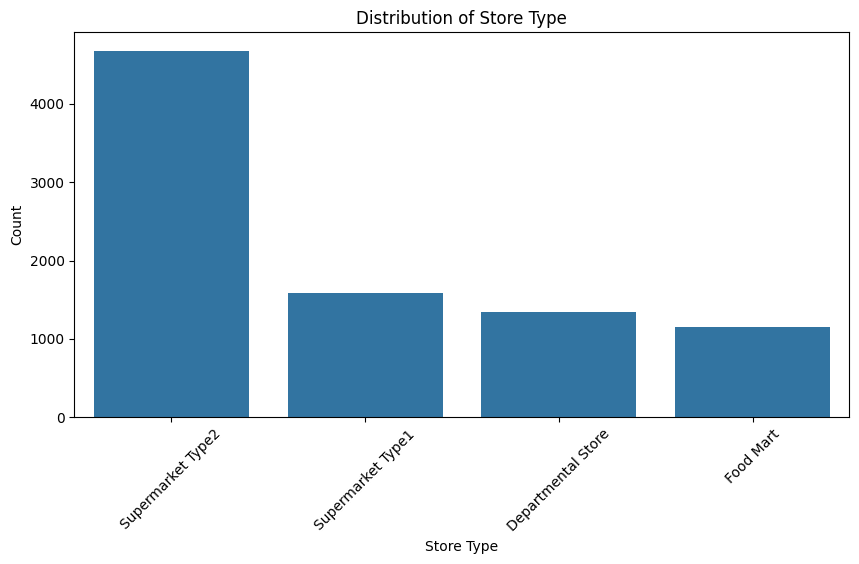

In [ ]:
#For Store_Type:
# Shows the frequency of each store type
plt.figure(figsize=(10, 5))
sns.countplot(
    data=data,
    x='Store_Type',
    order=data['Store_Type'].value_counts().index
)

plt.title('Distribution of Store Type')
plt.xlabel('Store Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Observations:
- There are four store types represented in the dataset: Supermarket Type2, Supermarket Type1, Departmental Store, and Food Mart.
- Supermarket Type2 is by far the most common store type, with roughly 4,600–4,700 observations.
- Supermarket Type1 is the second most frequent category, with approximately 1,600 observations.
- Departmental Store has around 1,300–1,400 observations.
- Food Mart is the least represented category, with approximately 1,100–1,200 observations.
- The distribution is highly uneven across store types.
- Supermarket Type2 has almost three times as many observations as Supermarket Type1.
- The three less frequent store types are relatively close to one another compared with the much larger Supermarket Type2 category.
- More than half of the dataset records belong to Supermarket Type2.
- This graph shows how frequently each store type appears in the dataset, it does not by itself indicate which store type generates more sales or performs better.

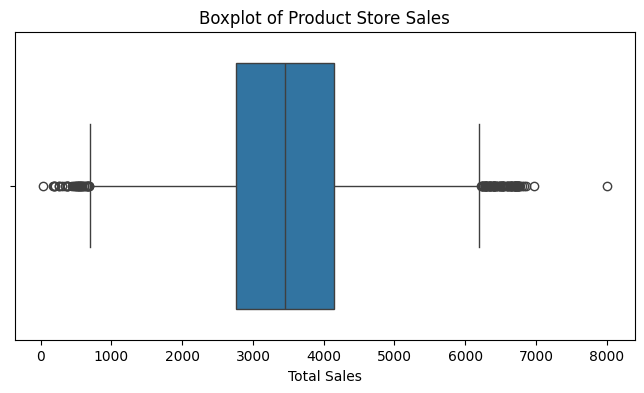

In [ ]:
#For Product_Store_Sales_Total:
# Shows the median, quartiles and possible high/low sales outliers
plt.figure(figsize=(8, 4))
sns.boxplot(
    data=data,
    x='Product_Store_Sales_Total'
)

plt.title('Boxplot of Product Store Sales')
plt.xlabel('Total Sales')
plt.show()

Observations:
- The median total sales value is approximately 3,500.
- The first quartile appears to be around 2,700–2,800.
- The third quartile appears to be around 4,200.
- Therefore, the middle 50% of observations are concentrated approximately between 2,700 and 4,200.
- The median is fairly close to the center of the box, which supports an approximately symmetric distribution.
- The lower whisker extends to approximately 700.
- The upper whisker extends to approximately 6,200.
- There are several potential outliers below the lower whisker.
- Low-end outliers appear mostly between roughly 100 and 700.
- There are also several potential high-end outliers above approximately 6,200.
- Most high-end outliers appear between roughly 6,200 and 7,000.
- There is at least one particularly extreme high value close to 8,000.
- Potential outliers occur on both sides of the distribution, although the highest observation extends noticeably farther from the main range.
- These points should not automatically be treated as errors, since they may represent valid cases of unusually low or high sales.

## Bivariate Analysis

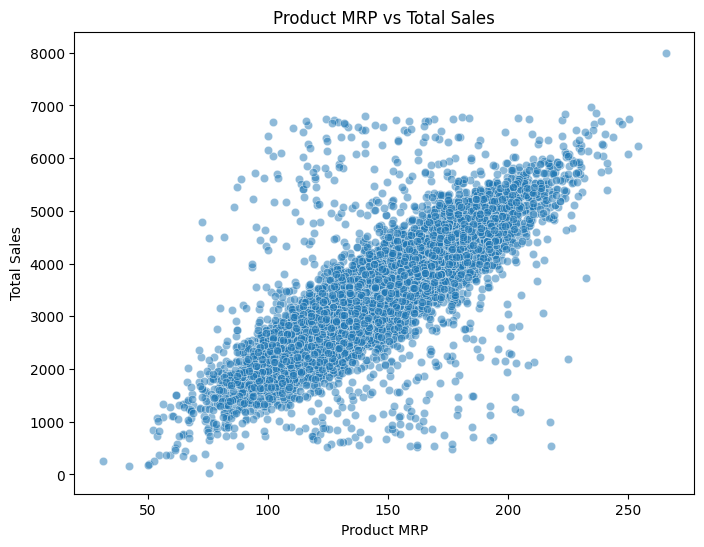

In [ ]:
#For Product MRP vs Total Sales:
# Relationship between product price and total sales
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x="Product_MRP",
    y="Product_Store_Sales_Total",
    alpha=0.5
)

plt.title("Product MRP vs Total Sales")
plt.xlabel("Product MRP")
plt.ylabel("Total Sales")
plt.show()

Observations:
- There is a clear positive relationship between Product_MRP and Product_Store_Sales_Total.
- As product MRP increases, total sales generally increase as well.
- The point cloud forms an upward diagonal pattern, which suggests a fairly strong positive association.
- Products with low MRP tend to have lower total sales.
- Products with high MRP tend to have higher total sales.
- The spread of sales values becomes somewhat wider at higher MRP values.
- There are some observations that fall well above or below the main pattern, indicating possible unusual cases or outliers.
- One especially high observation appears near an MRP above 250 with sales close to 8,000.
- Product_MRP appears to be strongly associated with total sales.
- Higher-priced products tend to generate higher total revenue.
- This does not prove causation, but MRP looks like an important variable for explaining sales variation.

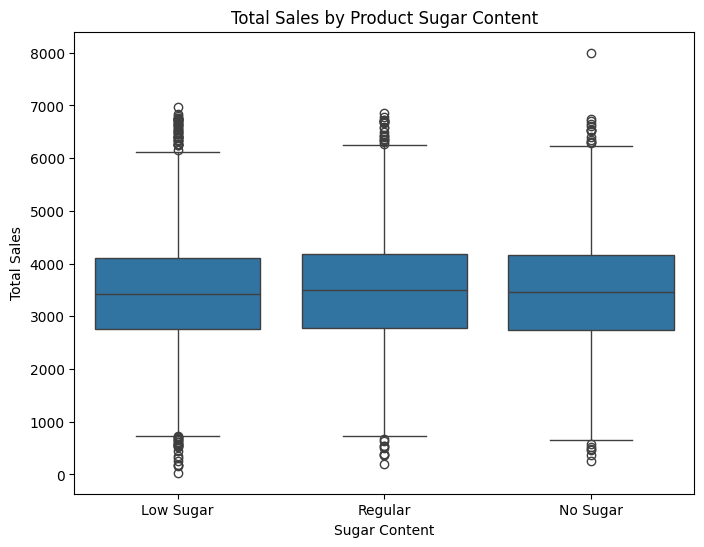

In [ ]:
#For Sugar Content vs Total Sales:
# Compare the sales distributions of the different sugar-content categories
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=data,
    x="Product_Sugar_Content",
    y="Product_Store_Sales_Total"
)

plt.title("Total Sales by Product Sugar Content")
plt.xlabel("Sugar Content")
plt.ylabel("Total Sales")
plt.show()

Observations:
- The three sugar-content categories have very similar median sales values.
- Low Sugar, Regular, and No Sugar all have medians around the mid-3,000 range.
- The interquartile ranges are also very similar across the three categories.
- There is substantial overlap among all three distributions.
- All categories contain both low-end and high-end outliers.
- No Sugar includes one especially high outlier near 8,000.
- None of the categories appears dramatically different from the others in terms of central sales values.
- Product_Sugar_Content does not appear to have a strong relationship with total sales.
- The sales distributions are very similar across low-sugar, regular, and no-sugar products.
- Sugar classification alone likely explains little of the variation in total sales.

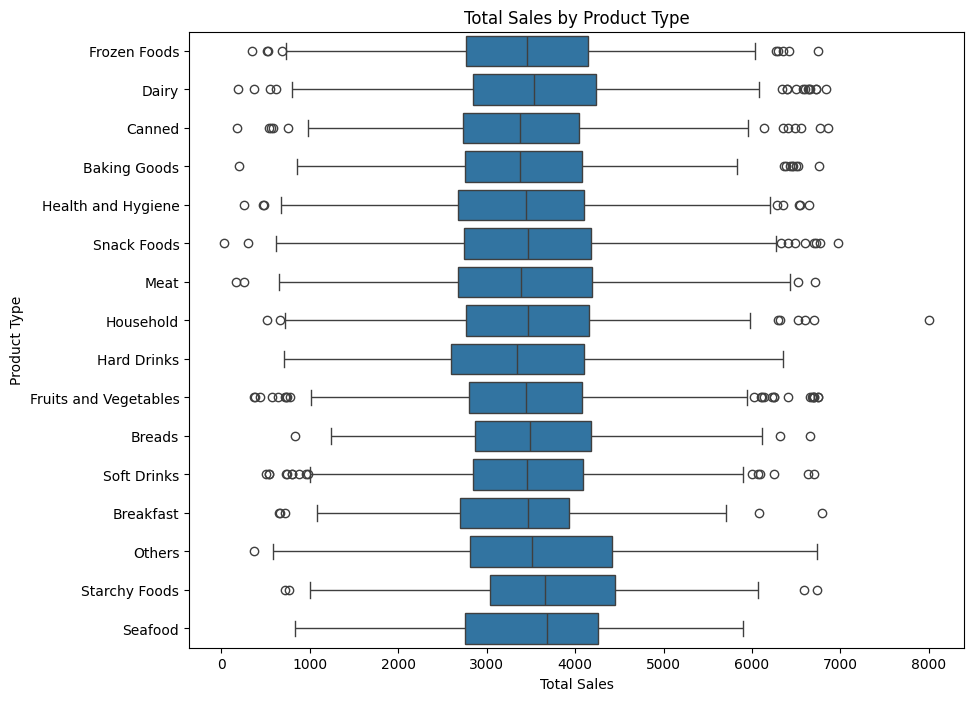

In [ ]:
#For Product Type vs Total Sales:
# Compare sales distributions across product categories
plt.figure(figsize=(10, 8))

sns.boxplot(
    data=data,
    y="Product_Type",
    x="Product_Store_Sales_Total"
)

plt.title("Total Sales by Product Type")
plt.xlabel("Total Sales")
plt.ylabel("Product Type")
plt.show()

Observations:
- Median sales are fairly similar across many product categories.
- Most product types have median sales around approximately 3,300–3,700.
- Others, Starchy Foods, and Seafood appear to have somewhat higher medians than several other categories.
- Breakfast and Hard Drinks appear slightly lower in median sales.
- There is substantial overlap among nearly all product-type distributions.
- Many product types contain both low and high outliers.
- Some categories have wider spreads than others.
- Household includes a particularly high outlier near 8,000.
- No single product type stands out as overwhelmingly different from all others.
- Product type may have some relationship with total sales, but the differences are modest.
- The large overlap between categories suggests product type alone is not a dominant explanation for sales differences.
- Some categories may perform somewhat differently, but further statistical testing would be useful before making a strong claim.

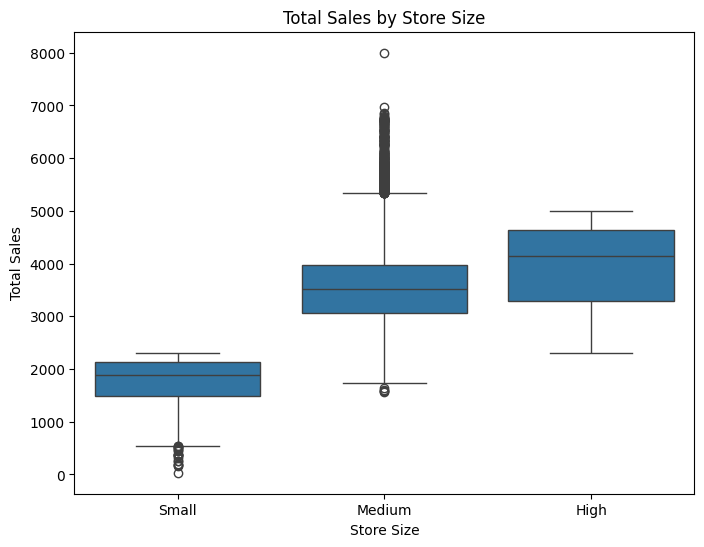

In [ ]:
#For Store Size vs Total Sales:
# Define logical order of store sizes
size_order = ["Small", "Medium", "High"]

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=data,
    x="Store_Size",
    y="Product_Store_Sales_Total",
    order=size_order
)

plt.title("Total Sales by Store Size")
plt.xlabel("Store Size")
plt.ylabel("Total Sales")
plt.show()

Observations:
- Sales increase clearly across the store-size categories.
- Small stores have the lowest median sales, around 1,800.
- Medium stores have a median around 3,500.
- High stores have the highest median, around 4,100.
- The three distributions are noticeably separated.
- High-sized stores generally have larger sales values than medium stores.
- Medium stores show many high-side outliers.
- Small stores include several unusually low observations.
- The overall pattern suggests a strong ordered relationship between store size and sales.
- Store size appears to be strongly associated with total sales.
- Larger stores tend to generate higher product-store sales.
- High stores have the highest typical sales, while Small stores have the lowest.

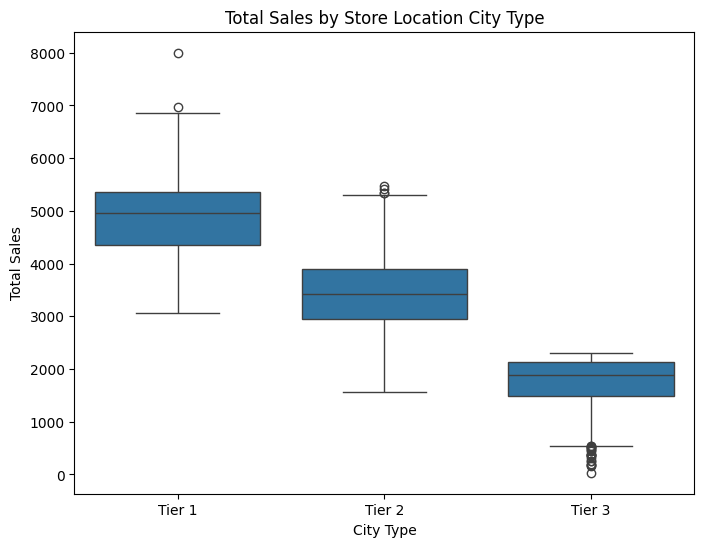

In [ ]:
#For City Type vs Total Sales:
# Compare sales distributions across city tiers
tier_order = ["Tier 1", "Tier 2", "Tier 3"]

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=data,
    x="Store_Location_City_Type",
    y="Product_Store_Sales_Total",
    order=tier_order
)

plt.title("Total Sales by Store Location City Type")
plt.xlabel("City Type")
plt.ylabel("Total Sales")
plt.show()

Observations:
- The sales distributions differ strongly among the three city tiers.
- Tier 1 has the highest median sales, close to 5,000.
- Tier 2 has a lower median, around 3,400.
- Tier 3 has the lowest median, around 1,800.
- There is a clear descending pattern from Tier 1 to Tier 3.
- Tier 1 also has a relatively high upper range.
- Tier 3 includes several very low outliers.
- Tier 2 contains some high-side outliers but remains clearly below Tier 1 in central tendency.
- The differences are very pronounced.
- Store location city type appears to be strongly related to total sales.
- Tier 1 locations tend to have the highest sales, followed by Tier 2, with Tier 3 having the lowest.
- Based on the data dictionary, this may be consistent with the higher standard of living associated with Tier 1 cities, although the graph itself does not establish the cause of the sales difference.

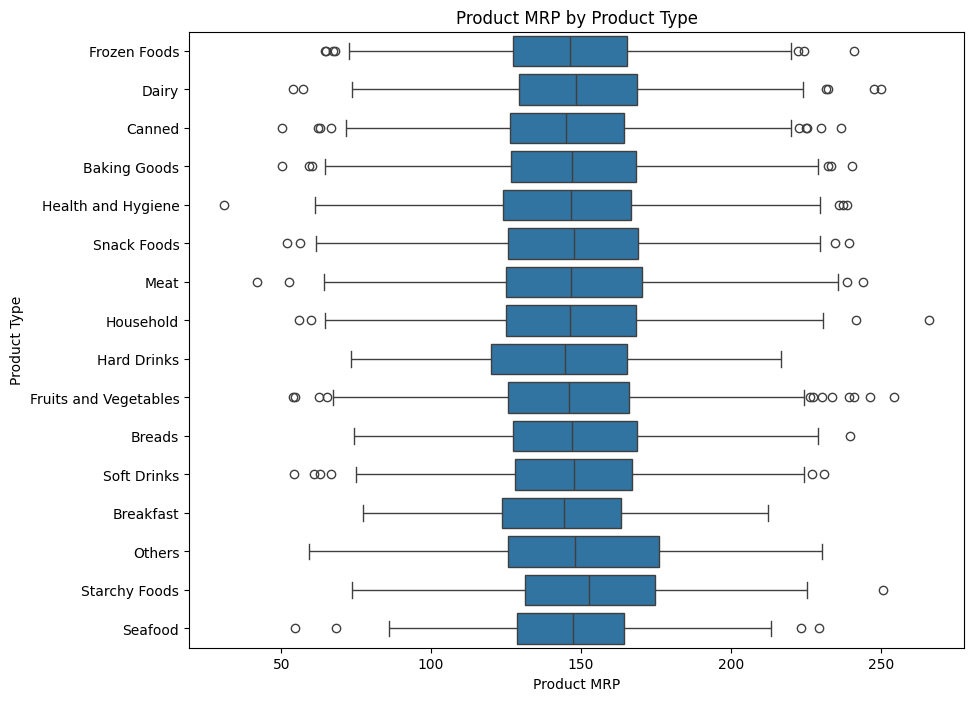

In [ ]:
#For Product Type vs MRP:
# Compare product prices across product categories
plt.figure(figsize=(10, 8))

sns.boxplot(
    data=data,
    y="Product_Type",
    x="Product_MRP"
)

plt.title("Product MRP by Product Type")
plt.xlabel("Product MRP")
plt.ylabel("Product Type")
plt.show()

Observations:
- Median MRP values are relatively similar across most product types.
- Most product types have median MRP values around 140–155.
- The boxes overlap substantially, indicating similar price distributions across categories.
- Starchy Foods and Others appear to have slightly higher median MRP values than several other categories.
- Hard Drinks appears to have a somewhat lower median than many categories.
- The interquartile ranges are also fairly similar across most product types.
- Numerous low- and high-MRP outliers occur across the categories.
- Some extreme high-MRP values appear for categories such as Household, Starchy Foods, Dairy, and Fruits and Vegetables.
- No product category is clearly separated from the others in terms of MRP.
- Product type does not appear to have a strong relationship with MRP.
- Although there are small differences between categories, product prices have considerable overlap across product types.
- Product type alone therefore appears to explain relatively little of the variation in MRP.

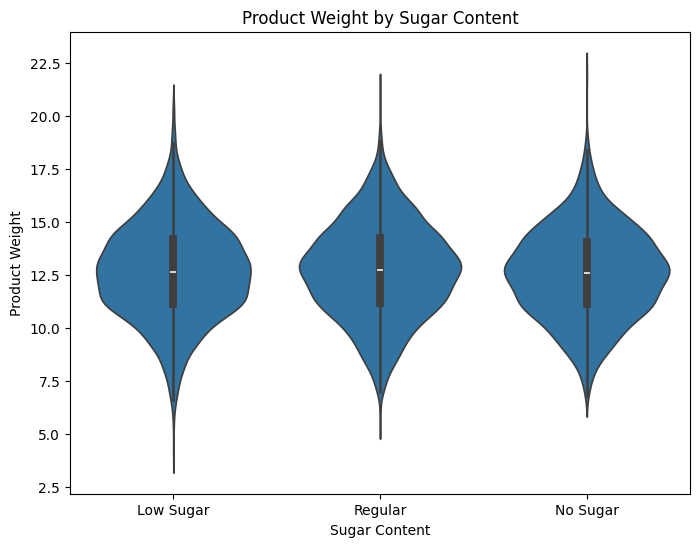

In [ ]:
#For Sugar Content vs Product Weight:
# Compare product weights across sugar-content categories
plt.figure(figsize=(8, 6))

sns.violinplot(
    data=data,
    x="Product_Sugar_Content",
    y="Product_Weight"
)

plt.title("Product Weight by Sugar Content")
plt.xlabel("Sugar Content")
plt.ylabel("Product Weight")
plt.show()

Observations:
- The three violin plots have very similar shapes.
- All three categories are centered at approximately 12.5–13.
- The distributions appear relatively symmetric.
- The widest portions of the violins occur around roughly 11–14, showing that most products fall within this weight range.
- Median values are nearly identical among the three sugar-content groups.
- Their interquartile ranges also appear very similar.
- All three distributions extend to both relatively low and relatively high weights.
- There is no obvious separation between Low Sugar, Regular, and No Sugar.
- Product weight does not appear to differ meaningfully according to sugar content.
- Sugar classification and product weight appear to have little association in this dataset.

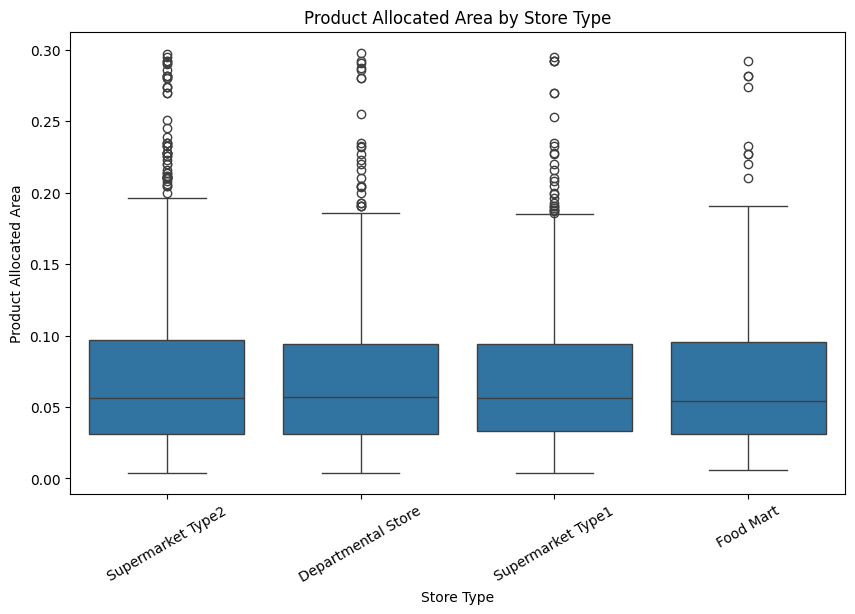

In [ ]:
#For Store Type vs Product Allocated Area:
# Examine whether products receive different amounts of display space
# depending on the type of store
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="Store_Type",
    y="Product_Allocated_Area"
)

plt.title("Product Allocated Area by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Product Allocated Area")

plt.xticks(rotation=30)
plt.show()

Observations:
- The four store types have nearly identical median allocated-area values.
- Median allocated area is approximately 0.055 for each group.
- Their interquartile ranges are also extremely similar.
- The upper whiskers extend to roughly 0.19 for all four store types.
- Every store type contains high allocated-area outliers.
- Outliers extend as high as approximately 0.29–0.30.
- The overall shapes and spreads of the distributions are remarkably similar.
- No store type appears to systematically allocate substantially more display area to individual products.
- Store type appears to have very little relationship with product allocated area.
- Product display-area allocation follows a similar distribution regardless of store type.

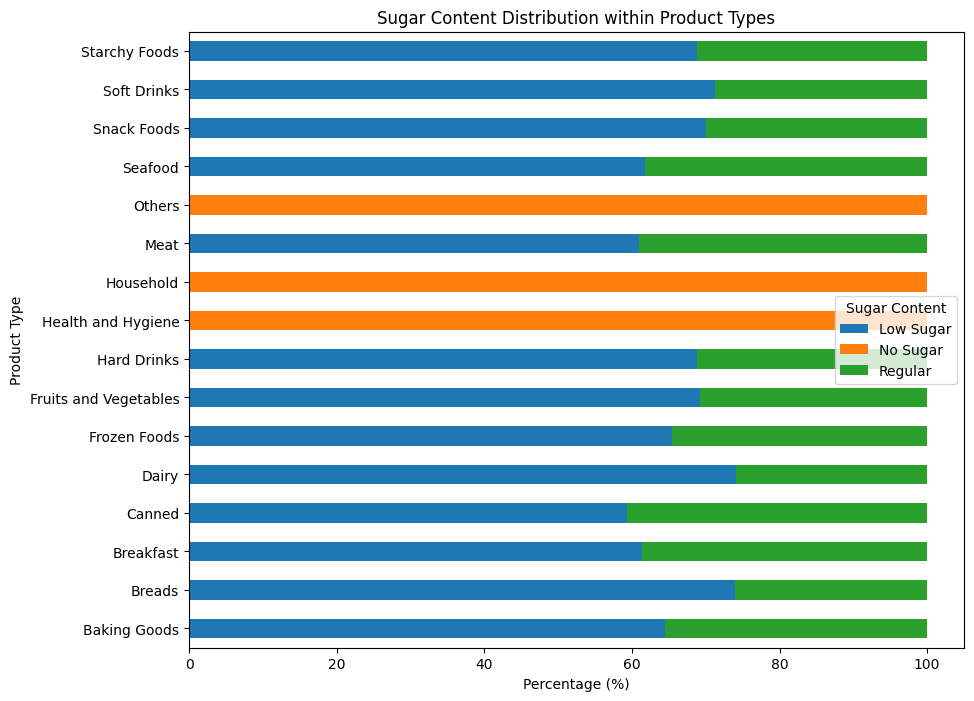

In [ ]:
#For Product Type vs Sugar Content:
# Create a cross-tabulation between product type and sugar content
product_sugar_table = pd.crosstab(
    data["Product_Type"],
    data["Product_Sugar_Content"],
    normalize="index"
) * 100

# Create a stacked percentage bar chart
product_sugar_table.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 8)
)

plt.title("Sugar Content Distribution within Product Types")
plt.xlabel("Percentage (%)")
plt.ylabel("Product Type")
plt.legend(title="Sugar Content")
plt.show()

Observations:
- Most product types contain only Low Sugar and Regular observations.
- For many categories, Low Sugar accounts for approximately 60–75% of observations.
- Regular generally accounts for the remaining approximately 25–40%.
- Others, Household, and Health and Hygiene appear to consist entirely of No Sugar products. Those categories show essentially 100% No Sugar.
- Product categories such as Dairy, Breads, and Soft Drinks have relatively high proportions of Low Sugar products.
- Canned, Seafood, and Meat have somewhat larger Regular shares compared with several other categories.
- The relationship is clearly not random: certain product types are strongly associated with particular sugar-content classifications.
- The graph suggests that Product_Type and Product_Sugar_Content are related categorical variables.
- There is a clear association between product type and sugar-content classification.
- In particular, Others, Household, and Health and Hygiene are entirely classified as No Sugar, while most food-related categories consist predominantly of Low Sugar and Regular products.
- This is also logically consistent with some categories containing non-food products, for which a sugar classification may function differently.

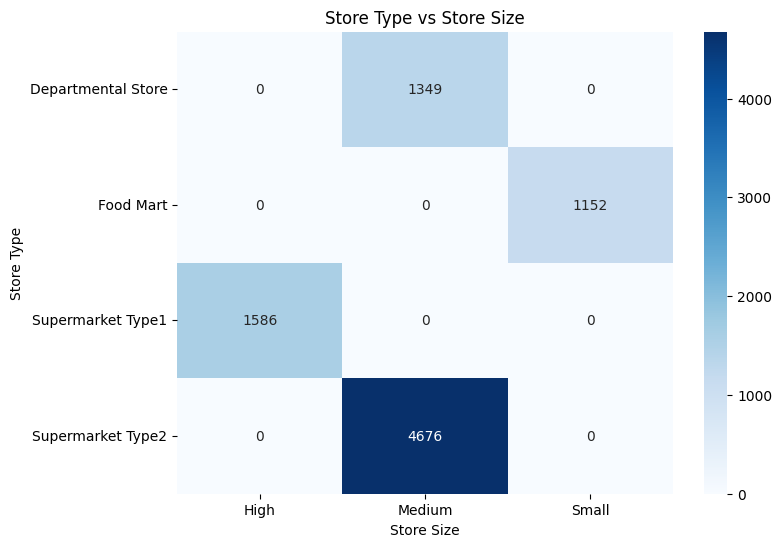

In [ ]:
#For Store Type vs Store Size:
# Create a contingency table of store type and store size
store_type_size = pd.crosstab(
    data["Store_Type"],
    data["Store_Size"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    store_type_size,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Store Type vs Store Size")
plt.xlabel("Store Size")
plt.ylabel("Store Type")
plt.show()

Observations:
- Departmental Store appears only with Medium-sized stores, with 1,349 observations.
- Food Mart appears only with Small stores, with 1,152 observations.
- Supermarket Type1 appears only with High stores, with 1,586 observations.
- Supermarket Type2 appears only with Medium stores, with 4,676 observations.
- All other store-type/store-size combinations have a count of zero.
- Therefore, store type and store size are not independently distributed.
- Knowing the store type allows you to determine its store-size category in this dataset.
- Medium stores contain two types: Departmental Store and Supermarket Type2.
- High stores correspond exclusively to Supermarket Type1.
- Small stores correspond exclusively to Food Mart.
- Store_Type and Store_Size have an extremely strong, essentially deterministic association in this dataset.

## Multivariate Analysis

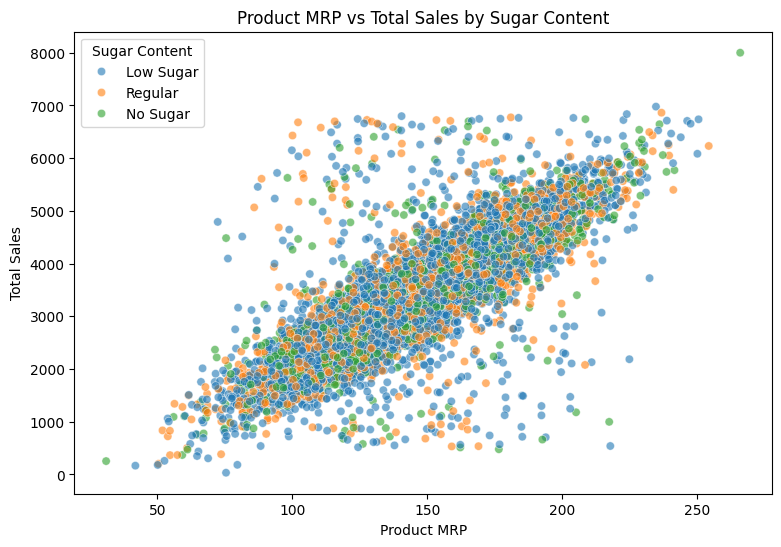

In [ ]:
#For MRP vs Sales by Sugar Content:
# Relationship between price and sales, separated by sugar category
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=data,
    x="Product_MRP",
    y="Product_Store_Sales_Total",
    hue="Product_Sugar_Content",
    alpha=0.6
)

plt.title("Product MRP vs Total Sales by Sugar Content")
plt.xlabel("Product MRP")
plt.ylabel("Total Sales")
plt.legend(title="Sugar Content")
plt.show()

Observations:
- There is a clear positive relationship between Product MRP and Total Sales for all three sugar-content categories.
- As MRP increases, sales generally increase regardless of whether the product is Low Sugar, Regular, or No Sugar.
- The three colors overlap heavily throughout the graph.
- No sugar-content category forms a clearly separate price-sales pattern.
- Low Sugar has many more observations, which is consistent with its larger representation in the dataset.
- Regular and No Sugar observations generally follow the same upward trend as Low Sugar.
- High and low sales outliers occur within multiple sugar-content categories.
- The extreme sales value close to 8,000 belongs to a No Sugar observation, but a single point does not indicate that No Sugar products generally sell more.
- The positive MRP-sales relationship appears to exist independently of sugar-content classification.
- Sugar content does not appear to substantially modify the relationship between price and total sales.
- MRP seems considerably more informative about total sales than sugar content.

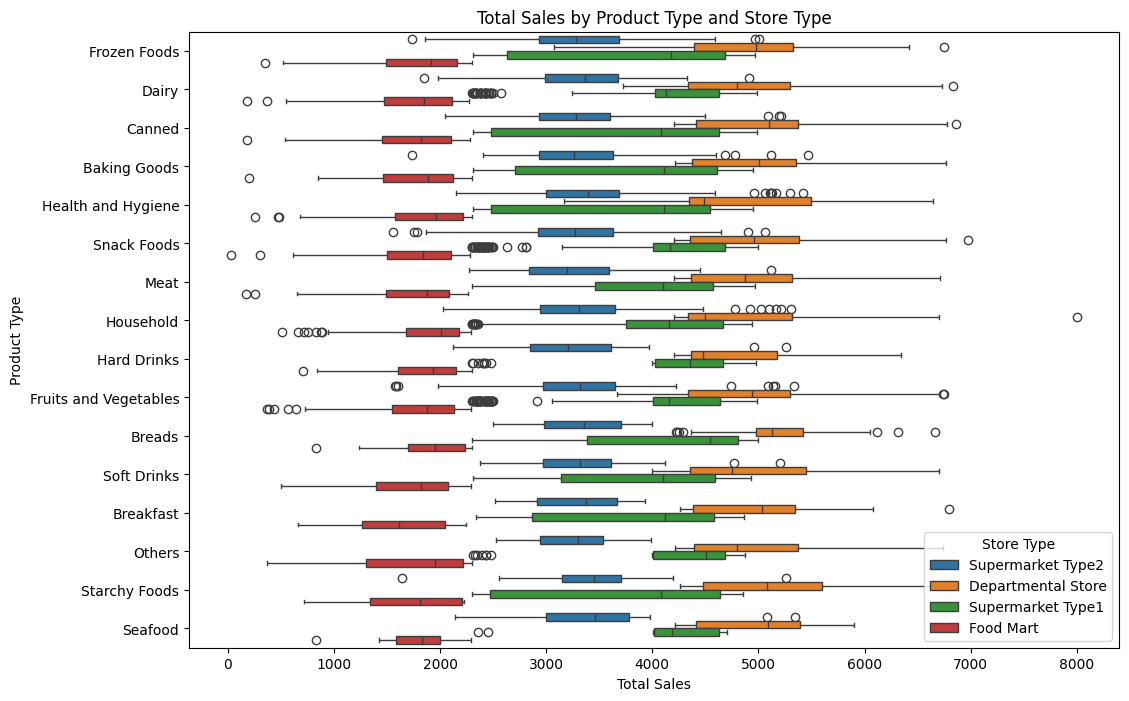

In [ ]:
#For Sales by Product Type and Store Type:
# Compare product-category sales across store types
plt.figure(figsize=(12, 8))

sns.boxplot(
    data=data,
    y="Product_Type",
    x="Product_Store_Sales_Total",
    hue="Store_Type"
)

plt.title("Total Sales by Product Type and Store Type")
plt.xlabel("Total Sales")
plt.ylabel("Product Type")
plt.legend(title="Store Type")
plt.show()

Observations:
- Store type produces a clear difference in sales across almost every product category.
- Departmental Store generally has the highest sales distributions across product types.
- Supermarket Type1 generally has the second-highest values.
- Supermarket Type2 tends to be lower than those two.
- Food Mart generally has the lowest sales distribution.
- This ordering is fairly consistent across many different product types.
- Differences between store types are larger than differences between many product categories.
- Within a given store type, product-type medians are relatively similar in many cases.
- Several product types contain outliers, but the overall store-type pattern remains visible.
- This suggests that the store environment may be more strongly associated with sales than the specific broad product category.
- Store_Type appears to explain much more of the variation in total sales than Product_Type.
- Product type may contribute some differences, but the same broad ordering of store types persists across most product categories.
- It seems that store-level characteristics are particularly important in this dataset.

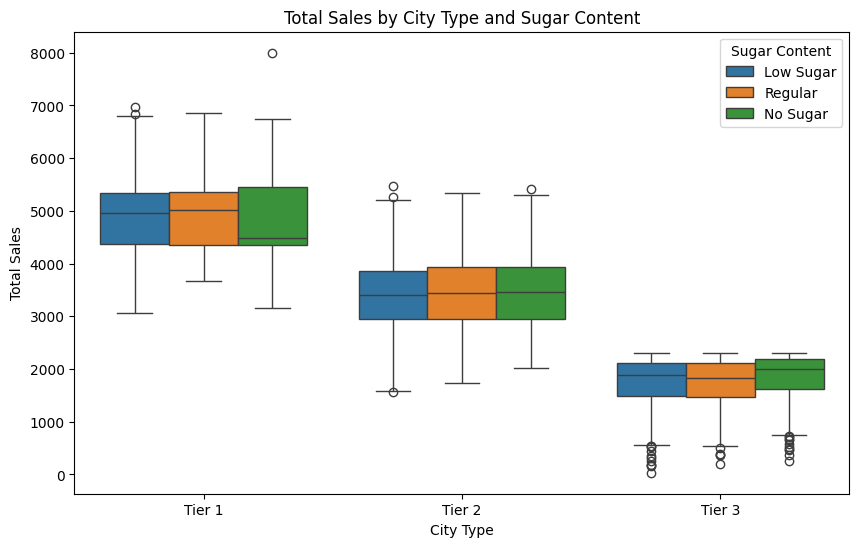

In [41]:
#For Sales by City Tier and Product Sugar Content:
# Analyze sales across city tiers while separating sugar-content categories
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="Store_Location_City_Type",
    y="Product_Store_Sales_Total",
    hue="Product_Sugar_Content",
    order=["Tier 1", "Tier 2", "Tier 3"]
)

plt.title("Total Sales by City Type and Sugar Content")
plt.xlabel("City Type")
plt.ylabel("Total Sales")
plt.legend(title="Sugar Content")
plt.show()

Observations:
- Tier 1 stores show the highest sales across all sugar-content categories.
- Tier 2 stores show intermediate sales.
- Tier 3 stores show the lowest sales.
- Within each city tier, Low Sugar, Regular, and No Sugar have fairly similar medians.
- The difference between city tiers is substantially larger than the difference between sugar-content categories.
- The Tier 1 distributions center around approximately 5,000 in sales.
- Tier 2 distributions center around approximately 3,300–3,500.
- Tier 3 distributions center around approximately 1,800–2,000.
- No Sugar in Tier 1 contains the extreme observation near 8,000.
- Despite that outlier, there is no obvious general sugar-content advantage within the tiers.
- City tier appears much more strongly associated with sales than product sugar content.
- The ranking Tier 1 > Tier 2 > Tier 3 persists across sugar-content categories.
- However, city type is strongly associated with store type in this dataset, so this graph cannot determine whether city tier itself is responsible for these differences.

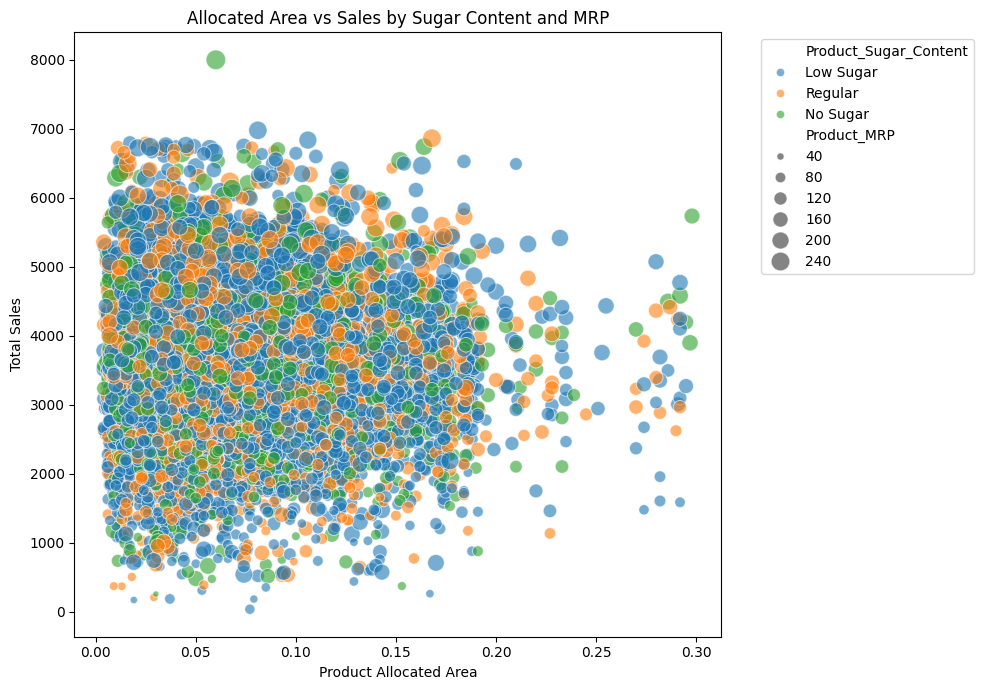

In [42]:
#For Allocated Area vs Sales, Using MRP and Sugar Content:
# More display dimensions are represented simultaneously:
# x-axis = allocated area
# y-axis = total sales
# color = sugar content
# marker size = MRP
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=data,
    x="Product_Allocated_Area",
    y="Product_Store_Sales_Total",
    hue="Product_Sugar_Content",
    size="Product_MRP",
    sizes=(20, 200),
    alpha=0.6
)

plt.title("Allocated Area vs Sales by Sugar Content and MRP")
plt.xlabel("Product Allocated Area")
plt.ylabel("Total Sales")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


Observations:
- There is no clear positive relationship between allocated area and sales.
- High and low sales occur throughout the lower allocated-area range.
- The three sugar-content colors are highly intermixed.
- No sugar-content group occupies a clearly distinct part of the graph.
- Larger bubbles, which represent higher MRP values, tend to occur at higher sales values more frequently.
- Bubble size does not appear to systematically increase as allocated area increases.
- Therefore, MRP and allocated area also appear largely unrelated.
- Most observations remain concentrated below approximately 0.15 allocated area.
- The few products with very high allocated area do not consistently have exceptionally high sales.
- This graph reinforces that Product_MRP is much more strongly associated with total sales than Product_Allocated_Area.
- Neither sugar content nor allocated area produces a strong visible separation in sales.
- Allocating more display space alone does not appear sufficient to explain higher sales.

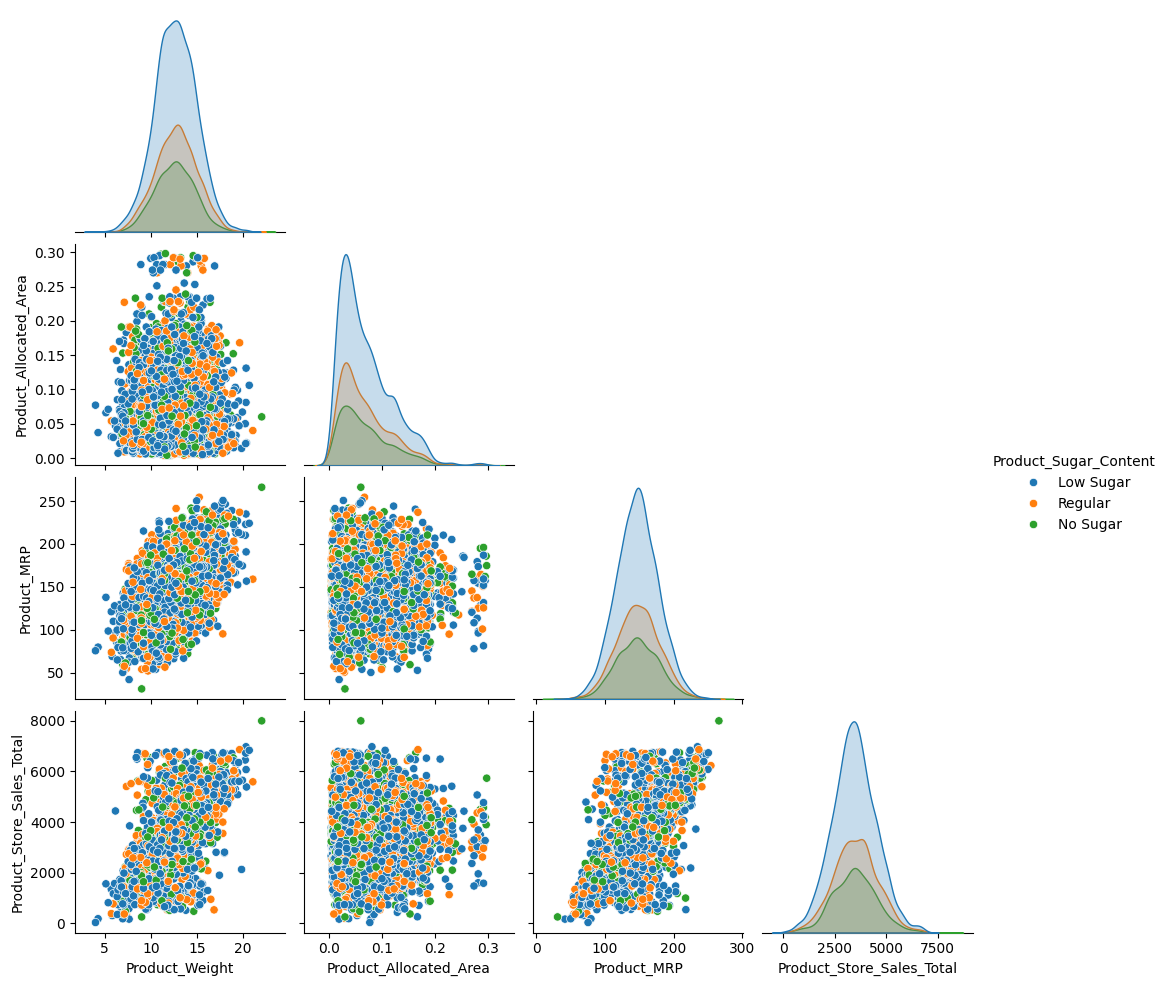

In [43]:
#For Numerical Variables by Sugar Content:
# Compare all important numerical variables simultaneously
sns.pairplot(
    data[
        [
            "Product_Weight",
            "Product_Allocated_Area",
            "Product_MRP",
            "Product_Store_Sales_Total",
            "Product_Sugar_Content"
        ]
    ],
    hue="Product_Sugar_Content",
    corner=True
)

plt.show()

Observations:
- Product_Weight has an approximately normal distribution for all sugar-content groups.
- Product_MRP also has a roughly bell-shaped distribution across the sugar groups.
- Product_Allocated_Area remains strongly right-skewed for each sugar category.
- Product_Store_Sales_Total has a roughly bell-shaped distribution for all three sugar groups.
- The sugar-content groups strongly overlap in nearly every numerical-variable relationship.
- Product Weight and Product MRP show a visible positive relationship.
- Product Weight and Total Sales show a clear positive relationship.
- Product MRP and Total Sales show an even stronger positive relationship.
- Product Allocated Area shows little obvious relationship with Product Weight.
- Product Allocated Area shows little relationship with MRP.
- Product Allocated Area also shows little clear relationship with sales.
- No sugar-content category produces a clearly different numerical pattern.
- The larger number of blue points primarily reflects the larger number of Low Sugar observations in the dataset rather than a necessarily stronger relationship.
- The pairplot confirms that the strongest numerical relationships involve Product_MRP, Product_Weight, and Product_Store_Sales_Total.
- Product_Allocated_Area appears mostly independent of the other numerical variables.
- Sugar content does not substantially change these relationships.

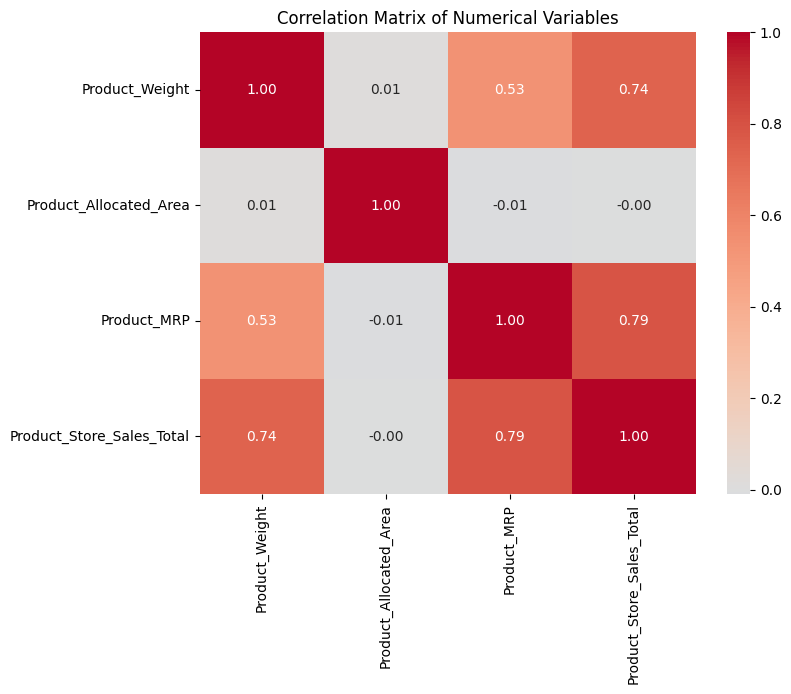

In [44]:
#For Correlation Heatmap of Numerical Variables:
# Select the numerical variables that are meaningful for correlation analysis
numeric_columns = [
    "Product_Weight",
    "Product_Allocated_Area",
    "Product_MRP",
    "Product_Store_Sales_Total"
]

# Calculate Pearson correlations
correlation_matrix = data[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

Observations:
- Product_MRP shows the strongest positive correlation with Product_Store_Sales_Total, with a coefficient of 0.79, indicating that higher product prices tend to be associated with higher total sales.
- Product_Weight is also strongly positively correlated with total sales (r = 0.74), suggesting that heavier products tend to be associated with greater sales values.
- The relationship between Product_Weight and Product_MRP is moderately positive (r = 0.53). This suggests that product weight and price share some degree of association, although the relationship is not especially strong.
- In contrast, Product_Allocated_Area has correlations close to zero with Product_Weight (r = 0.01), Product_MRP (r ≈ -0.01), and Product_Store_Sales_Total (r ≈ 0.00).
- Overall, Product_Allocated_Area does not appear to have a meaningful linear relationship with the other numerical variables.
- Among the numerical variables analyzed, MRP and product weight show the clearest linear associations with total sales, while allocated area shows little to no linear association.

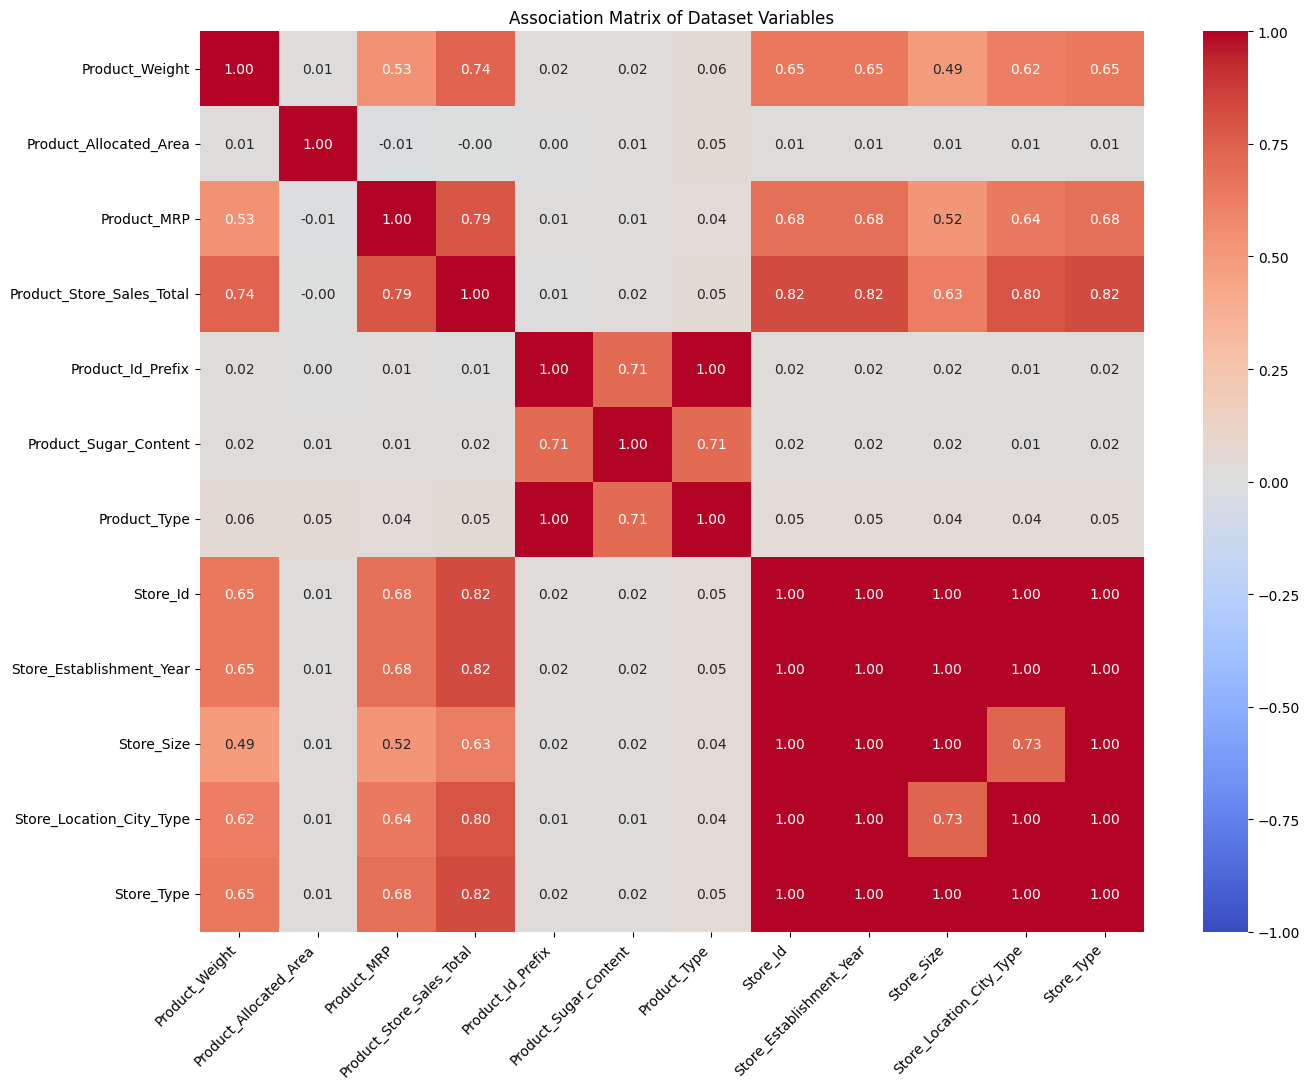

In [46]:
# For Correlation Matrix of Every Variable:
from scipy.stats import chi2_contingency

# ---------------------------------------------------------
# Variables to include
# ---------------------------------------------------------

# Numerical variables
numerical_cols = [
    "Product_Weight",
    "Product_Allocated_Area",
    "Product_MRP",
    "Product_Store_Sales_Total"
]

# Categorical variables
categorical_cols = [
    "Product_Id_Prefix",
    "Product_Sugar_Content",
    "Product_Type",
    "Store_Id",
    "Store_Establishment_Year",
    "Store_Size",
    "Store_Location_City_Type",
    "Store_Type"
]

all_cols = numerical_cols + categorical_cols


# ---------------------------------------------------------
# Function 1: Cramer's V
# Used for categorical vs categorical variables
# ---------------------------------------------------------

def cramers_v(x, y):

    # Create contingency table
    confusion_matrix = pd.crosstab(x, y)

    # Perform Chi-square test
    chi2 = chi2_contingency(confusion_matrix)[0]

    # Number of observations
    n = confusion_matrix.sum().sum()

    # Dimensions of contingency table
    r, k = confusion_matrix.shape

    # Avoid division by zero
    if min(k - 1, r - 1) == 0:
        return 0

    # Calculate Cramer's V
    return np.sqrt((chi2 / n) / min(k - 1, r - 1))


# ---------------------------------------------------------
# Function 2: Correlation Ratio (Eta)
# Used for categorical vs numerical variables
# ---------------------------------------------------------

def correlation_ratio(categories, measurements):

    # Convert categories into integer codes
    categories = pd.factorize(categories)[0]

    # Overall mean of numerical variable
    overall_mean = np.mean(measurements)

    numerator = 0

    # Calculate variation between categories
    for category in np.unique(categories):

        values = measurements[categories == category]

        if len(values) > 0:
            category_mean = np.mean(values)

            numerator += (
                len(values)
                * (category_mean - overall_mean) ** 2
            )

    # Total variation
    denominator = np.sum(
        (measurements - overall_mean) ** 2
    )

    if denominator == 0:
        return 0

    return np.sqrt(numerator / denominator)

# ---------------------------------------------------------
# Create empty association matrix
# ---------------------------------------------------------

association_matrix = pd.DataFrame(
    np.zeros((len(all_cols), len(all_cols))),
    index=all_cols,
    columns=all_cols
)


# ---------------------------------------------------------
# Calculate relationship for every pair of variables
# ---------------------------------------------------------

for col1 in all_cols:
    for col2 in all_cols:

        # Same variable always has association = 1
        if col1 == col2:

            association_matrix.loc[col1, col2] = 1

        # Numerical vs Numerical
        elif col1 in numerical_cols and col2 in numerical_cols:

            association_matrix.loc[col1, col2] = (
                data[[col1, col2]]
                .corr()
                .iloc[0, 1]
            )

        # Categorical vs Categorical
        elif col1 in categorical_cols and col2 in categorical_cols:

            association_matrix.loc[col1, col2] = cramers_v(
                data[col1],
                data[col2]
            )

        # Categorical vs Numerical
        elif col1 in categorical_cols and col2 in numerical_cols:

            association_matrix.loc[col1, col2] = correlation_ratio(
                data[col1],
                data[col2]
            )

        # Numerical vs Categorical
        else:

            association_matrix.loc[col1, col2] = correlation_ratio(
                data[col2],
                data[col1]
            )


# ---------------------------------------------------------
# Plot the complete association matrix
# ---------------------------------------------------------

plt.figure(figsize=(14, 11))

sns.heatmap(
    association_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Association Matrix of Dataset Variables")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Observations:
- Product_MRP and Product_Store_Sales_Total show a strong association of about 0.79, while Product_Weight and total sales are also strongly related at around 0.74.
- Product_Weight and Product_MRP have a moderate association of approximately 0.53.
- These results indicate that MRP, weight, and total sales form the strongest group of related numerical variables in the dataset.
- In contrast, Product_Allocated_Area shows almost no association with Product_Weight, Product_MRP, or Product_Store_Sales_Total, with values close to 0.00. Its association with the store-related variables is also very weak.
- This suggests that allocated display area behaves largely independently from the other features.
- The store-related variables show a very high degree of overlap. Store_Id has an association of approximately 1.00 with Store_Establishment_Year, Store_Size, Store_Location_City_Type, and Store_Type.
- Store_Establishment_Year also shows perfect or near-perfect associations with several of these store characteristics.
- This indicates that the store variables are not independent from one another and may be describing much of the same underlying information.
- Store_Size and Store_Location_City_Type also have a strong association of about 0.73, suggesting that certain store sizes tend to occur within particular city tiers.
- Store characteristics are also strongly related to total sales. Store_Id, Store_Establishment_Year, and Store_Type each show associations of about 0.82 with Product_Store_Sales_Total.
- Store_Location_City_Type is also strongly associated with sales at around 0.80, while Store_Size has a somewhat lower, but still notable, association of approximately 0.63.
- This suggests that sales patterns differ substantially depending on the store context.
- Store-related variables are also associated with Product_MRP. Store_Id, Store_Establishment_Year, and Store_Type each have values near 0.68, while Store_Location_City_Type is around 0.64 and Store_Size around 0.52.
- A similar pattern appears for Product_Weight, with associations of about 0.65 for Store_Id, Store_Establishment_Year, and Store_Type, approximately 0.62 for Store_Location_City_Type, and about 0.49 for Store_Size.
- These results suggest that the distribution of product prices and weights varies across different store characteristics.
- Product_Id_Prefix and Product_Type have an association of approximately 1.00, indicating that the product ID prefix and product type contain almost identical information in this dataset.
- Because of this, Product_Id_Prefix may be redundant if Product_Type is already being used.
- Both Product_Id_Prefix and Product_Type have a strong association of about 0.71 with Product_Sugar_Content, suggesting that certain product groups are closely linked with particular sugar-content categories.
- Product_Sugar_Content has very weak associations with the numerical variables, generally between 0.00 and 0.02.
- Similarly, Product_Type has only weak associations with Product_Weight, Product_MRP, Product_Allocated_Area, and total sales, with values around 0.04–0.06.
- Therefore, neither sugar content nor product type appears to have a strong direct association with these numerical measures on its own.

# **Data Preprocessing**

Observations: The values in the Product_Sugar_Content column were replaced before doing the EDA segment.

### Exploring Patterns in Product_IDs
- The Product_Id column has two characters followed by a number. Let's see if there is a relation with other columns.

In [47]:
# Extracting the first two characters from the Product_Id column and storing it in another column
data["Product_Id_char"] = data["Product_Id"].str[:2]
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_Prefix,Product_Id_char
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,FD
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,FD
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,FD
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,FD
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,NC


In [48]:
data["Product_Id_char"].unique()

array(['FD', 'NC', 'DR'], dtype=object)

In [49]:
data.loc[data.Product_Id_char == "FD", "Product_Type"].unique()

array(['Frozen Foods', 'Dairy', 'Canned', 'Baking Goods', 'Snack Foods',
       'Meat', 'Fruits and Vegetables', 'Breads', 'Breakfast',
       'Starchy Foods', 'Seafood'], dtype=object)

In [50]:
data.loc[data.Product_Id_char == "DR", "Product_Type"].unique()

array(['Hard Drinks', 'Soft Drinks'], dtype=object)

In [51]:
data.loc[data.Product_Id_char == "NC", "Product_Type"].unique()

array(['Health and Hygiene', 'Household', 'Others'], dtype=object)

Observations:
- There is a Macro-Category Encoding: The initial two characters of Product_Id correspond directly to three broader product classifications:

FD: Food

DR: Drinks

NC: Non-Consumable

### Store's Age

A store which has been in the business for a long duration is more trustworthy than the newly established ones.

On the other hand, older stores may sometimes lack infrastructure if proper attention is not given. So let us calculate the current age of the store and incorporate that in our model.

In [52]:
# Outlet Age
data["Store_Age_Years"] = 2025 - data.Store_Establishment_Year #Subtracting it gives an interpretable metric representing the number of years a store has been active in business

### Grouping Product Types into Perishables and Non-Perishables

We have 16 different product types in our dataset.

So let us make two broad categories, perishables and non perishables, in order to reduce the number of product types.

In [53]:
perishables = [
    "Dairy",
    "Meat",
    "Fruits and Vegetables",
    "Breakfast",
    "Breads",
    "Seafood",
]

In [54]:
def change(x):
    if x in perishables:
        return "Perishables"
    else:
        return "Non Perishables"

In [55]:
data['Product_Type_Category'] = data['Product_Type'].apply(change)

In [56]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_Prefix,Product_Id_char,Store_Age_Years,Product_Type_Category
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,FD,16,Non Perishables
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,FD,26,Perishables
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,FD,38,Non Perishables
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,FD,38,Non Perishables
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,NC,27,Non Perishables


### Outlier Check

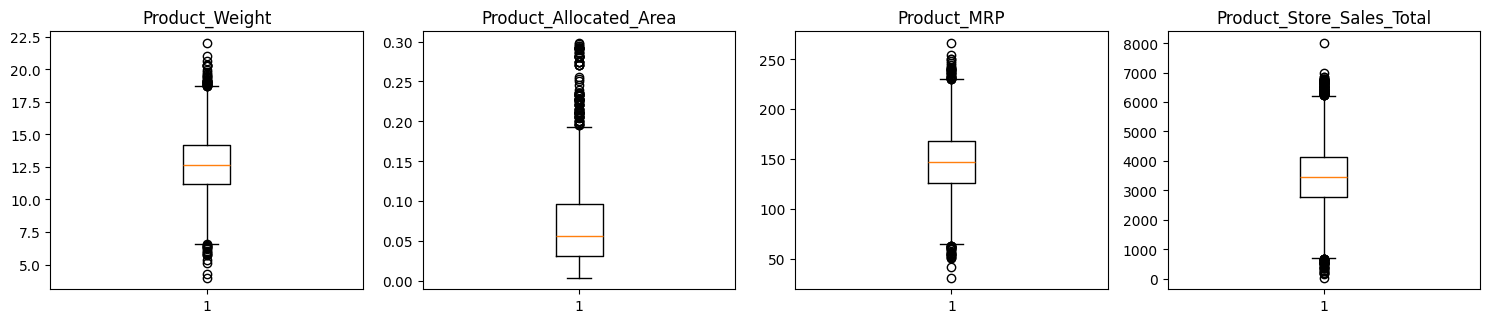

In [57]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()
numeric_columns.remove("Store_Establishment_Year")
numeric_columns.remove("Store_Age_Years")


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

Observations:
- There are many outliers, but they are valid datapoints, so they are not eliminated.

### Data Preparation for Modeling

- We aim to forecast the Product_Store_Sales_Total.
- Before building the model, we'll drop unnecessary columns and encode the categorical features.
- We'll then split the data into training and testing sets to evaluate the model's performance on unseen data.

In [58]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_Prefix,Product_Id_char,Store_Age_Years,Product_Type_Category
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,FD,16,Non Perishables
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,FD,26,Perishables
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,FD,38,Non Perishables
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,FD,38,Non Perishables
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,NC,27,Non Perishables


In [59]:
#Removing the columns that aren't required
data = data.drop(["Product_Id", "Product_Type", "Store_Id", "Store_Establishment_Year" , "Product_Id_Prefix"], axis=1)

In [60]:
data.shape

(8763, 11)

In [61]:
data.head()

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years,Product_Type_Category
0,12.66,Low Sugar,0.027,117.08,Medium,Tier 2,Supermarket Type2,2842.40,FD,16,Non Perishables
1,16.54,Low Sugar,0.144,171.43,Medium,Tier 1,Departmental Store,4830.02,FD,26,Perishables
2,14.28,Regular,0.031,162.08,High,Tier 2,Supermarket Type1,4130.16,FD,38,Non Perishables
3,12.10,Low Sugar,0.112,186.31,High,Tier 2,Supermarket Type1,4132.18,FD,38,Non Perishables
4,9.57,No Sugar,0.010,123.67,Small,Tier 3,Food Mart,2279.36,NC,27,Non Perishables


In [62]:
# Separating features and the target column
X = data.drop("Product_Store_Sales_Total", axis=1)
y = data["Product_Store_Sales_Total"]

In [63]:
# Splitting the data into train and test sets in 70:30 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, shuffle=True
)

In [64]:
X_train.shape, X_test.shape

((6134, 10), (2629, 10))

### Data Pre-processing Pipeline

To automatically encode all text and category features into numerical binary format for machine learning models.

In [65]:
categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_features

['Product_Sugar_Content',
 'Store_Size',
 'Store_Location_City_Type',
 'Store_Type',
 'Product_Id_char',
 'Product_Type_Category']

In [66]:
# Create a preprocessing pipeline for the categorical features

preprocessor = make_column_transformer(
    (Pipeline([('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
)

# **Model Building**

## Define functions for Model Evaluation

- We'll fit different models on the train data and observe their performance.
- We'll try to improve that performance by tuning some hyperparameters available for that algorithm.
- We'll use GridSearchCv for hyperparameter tuning and `r_2 score` to optimize the model.
- R-square - `Coefficient of determination` is used to evaluate the performance of a regression model. It is the amount of the variation in the output dependent attribute which is predictable from the input independent variables.
- Let's start by creating a function to get model scores, so that we don't have to use the same codes repeatedly.

In [67]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. Random Forest
4. AdaBoost
5. Gradient Boosting
6. XGBoost

### XGBoost Regressor

In [68]:
xgb_estimator = XGBRegressor(random_state=1)
xgb_estimator = make_pipeline(preprocessor,xgb_estimator)
xgb_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('xgbregressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              co...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, random_state=1, ...))])

In [69]:
#Checking model performance on training set
xgb_estimator_model_train_perf = model_performance_regression(xgb_estimator, X_train, y_train)
xgb_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,596.978222,468.965507,0.685033,0.684519,0.16569


In [70]:
#Checking model performance on test set
xgb_estimator_model_test_perf = model_performance_regression(xgb_estimator, X_test, y_test)
xgb_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.933034,485.429585,0.668482,0.667215,0.187421


Observations:
- There is a strong generalization (minimal overfitting), with both the training and test R2 being 0.685 and 0.668 respectively. The R2 indicates that on the test set, for example, the model accounts for roughly 66.8% of the variability in product sales using only the engineered and encoded features.
- Because the gap between train and test scores is very small, the model demonstrates strong stability and avoids severe memorization or variance issues.
- The MAE on the test set indicates that predictions deviate from actual product sales by an average of about 485 dollars.
- Considering that target sales span up to 8000 dollars with a std of over 1065 dollars, an average error of around 485 dollars is a solid baseline.

### Adaboost Regressor

In [71]:
ab_regressor = AdaBoostRegressor(random_state=1)
ab_regressor = make_pipeline(preprocessor,ab_regressor)
ab_regressor.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('adaboostregressor', AdaBoostRegressor(random_state=1))])

In [72]:
#Checking model performance on training set
ab_regressor_model_train_perf = model_performance_regression(ab_regressor, X_train, y_train)
ab_regressor_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,627.778405,512.191947,0.651694,0.651126,0.172981


In [73]:
#Checking model performance on test set
ab_regressor_model_test_perf = model_performance_regression(ab_regressor, X_test, y_test)
ab_regressor_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,647.483018,530.557049,0.633649,0.63225,0.193723


Observations:
- XGBoost outperforms AdaBoost across all evaluation metrics on the unseen test data. Adaboost had a lower R2 on the test data with a value of 0.633. Therefore, XGBoost explains approximately 3.5% more total variance in store sales.
- On average, AdaBoost's predictions deviate by 530.56 dollars per item. XGBoost saves roughly 45 dollars per forecast in absolute error, which reduces over-ordering and under-stocking risks across thousands of inventory items.
- Both models maintain strong generalization with narrow gaps between training and testing performance (AdaBoost test $R^2$ is 0.6336 vs. train 0.6517; XGBoost test $R^2$ is 0.6685 vs. train 0.6850). Neither model suffers from severe overfitting.

# **Model Performance Improvement - Hyperparameter Tuning**

### XGBoost Regressor

In [74]:
xgb_tuned = XGBRegressor(random_state=1)
xgb_tuned = make_pipeline(preprocessor, xgb_tuned)

# Grid of parameters to choose from
parameters = {
    "xgbregressor__n_estimators": [50, 100, 150],
    "xgbregressor__subsample": [0.7, 0.9, 1.0],
    "xgbregressor__gamma": [0, 1, 3],
    "xgbregressor__colsample_bytree": [0.7, 0.9, 1.0],
    "xgbregressor__colsample_bylevel": [0.7, 0.9, 1.0]
}

# Running the grid search
grid_obj = GridSearchCV(xgb_tuned, parameters, scoring='r2', cv=3, n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Setting the estimator to the best combination of parameters
xgb_tuned = grid_obj.best_estimator_

# Fitting the best algorithm to the data
xgb_tuned.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('xgbregressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              co...
                              feature_types=None, gamma=0, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=100, n_jobs=None,
                              num_parallel_tree=None, random_state=1, ...))])

In [75]:
#Checking model performance on training set
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
xgb_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.08229,468.850065,0.684923,0.684409,0.165625


In [76]:
# Checking model performance on test set
xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test, y_test)
xgb_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,616.107668,485.10883,0.668294,0.667027,0.187383


Observations:
- The tuned XGBoost model and the baseline model perform almost identically across every single metric.
- Test R2 remains at around 0.668, test MAE improved marginally by 0.32, from 485.43 to 485.11 dollars, while test RMSE saw a tiny increase of 0.18, from 615.93 to 616.11 dollars.
- The XGBoost's default settings were already well-calibrated for this dataset's balance between bias and variance.
- The train-to-test gap remains tight proving that the model generalizes robustly and does not overfit.

### Adaboost Regressor

In [77]:
ab_tuned = AdaBoostRegressor(random_state=1)
ab_tuned = make_pipeline(preprocessor, ab_tuned)

# Grid of parameters to choose from
parameters = {
    "adaboostregressor__n_estimators": [50, 75, 100, 150],
    "adaboostregressor__learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0]
}

# Running the grid search
grid_obj = GridSearchCV(ab_tuned, parameters, scoring='r2', cv=3, n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Setting the estimator to the best combination of parameters
ab_tuned = grid_obj.best_estimator_

# Fitting the best algorithm to the data
ab_tuned.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('adaboostregressor',
                 AdaBoostRegressor(learning_rate=0.01, random_state=1))])

In [78]:
# Checking model performance on training set
ab_tuned_model_train_perf = model_performance_regression(ab_tuned, X_train, y_train)
ab_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.816706,473.070121,0.684148,0.683632,0.166248


In [79]:
# Checking model performance on test set
ab_tuned_model_test_perf = model_performance_regression(ab_tuned, X_test, y_test)
ab_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.740955,488.848774,0.668689,0.667423,0.187821


Observations:
- Hyperparameter tuning dramatically improved AdaBoost across all evaluation metrics on the unseen test set. It closed the previous performance deficit, raising test R2 from approximately 63.4% to 66.9% and dropping test RMSE by around 31.7 points.
- The average absolute prediction error (MAE) decreased by over 41 dollars per product, making the model considerably more reliable for inventory demand planning.

# **Model Performance Comparison, Final Model Selection, and Serialization**

In [80]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        xgb_estimator_model_train_perf.T,
        xgb_tuned_model_train_perf.T,
        ab_regressor_model_train_perf.T,
        ab_tuned_model_train_perf.T,
    ],
    axis=1,
)

models_train_comp_df.columns = [
    "XGBoost Baseline",
    "XGBoost Tuned",
    "AdaBoost Baseline",
    "AdaBoost Tuned"
]

print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,XGBoost Baseline,XGBoost Tuned,AdaBoost Baseline,AdaBoost Tuned
RMSE,596.978222,597.082290,627.778405,597.816706
MAE,468.965507,468.850065,512.191947,473.070121
R-squared,0.685033,0.684923,0.651694,0.684148
Adj. R-squared,0.684519,0.684409,0.651126,0.683632
MAPE,0.165690,0.165625,0.172981,0.166248


In [81]:
# testing performance comparison

models_test_comp_df = pd.concat(
    [
        xgb_estimator_model_test_perf.T,
        xgb_tuned_model_test_perf.T,
        ab_regressor_model_test_perf.T,
        ab_tuned_model_test_perf.T,
    ],
    axis=1,
)

models_test_comp_df.columns = [
    "XGBoost Baseline",
    "XGBoost Tuned",
    "AdaBoost Baseline",
    "AdaBoost Tuned"
]

print("Testing performance comparison:")
models_test_comp_df

Testing performance comparison:


,XGBoost Baseline,XGBoost Tuned,AdaBoost Baseline,AdaBoost Tuned
RMSE,615.933034,616.107668,647.483018,615.740955
MAE,485.429585,485.108830,530.557049,488.848774
R-squared,0.668482,0.668294,0.633649,0.668689
Adj. R-squared,0.667215,0.667027,0.632250,0.667423
MAPE,0.187421,0.187383,0.193723,0.187821


Observations:
- AdaBoost Showed the Largest Improvement from Tuning because it was originally the weakest performer with a test R2 of 0.6336 and an RMSE of 647.48.
- After hyperparameter tuning, AdaBoost Tuned achieved an R2 of 0.6687 and dropped its RMSE to 615.74. This closed the performance gap completely, reducing absolute prediction error (MAE) by over 41 dollars per item (530.56 to 488.85 dollars).
- XGBoost Baseline achieved near-optimal results without any modifications.
- XGBoost Tuned delivered virtually identical results. This demonstrates that default XGBoost parameters were already well-regularized against variance and bias for this dataset.
- Both XGBoost models and the tuned AdaBoost model maintain tight generalization bounds: the train R2 sits around 0.684 to 0.685 while the test R2 settles at approximately 0.668.
- None of these models suffer from overfitting.
- The Recommended Final Model is either the XGBoost Baseline or XGBoost Tuned becaue they hava a lower average prediction error (MAE) compared to the Adaboost models. Also, the XGBoost achieves the lowest Mean Absolute Percentage Error on test data. It is also far more resilient to unseen shifts and extreme sales values than AdaBoost’s sequential residual re-weighting.

In [82]:
# Creating a folder for storing the files needed for web app deployment
os.makedirs("backend_files", exist_ok=True)

In [83]:
# Define the file path to save (serialize) the trained model along with the data preprocessing steps
saved_model_path = "backend_files/xgb_estimator.joblib"

In [84]:
# Save the best trained model pipeline using joblib
joblib.dump(xgb_estimator, saved_model_path)

print(f"Model saved successfully at {saved_model_path}")

Model saved successfully at backend_files/xgb_estimator.joblib


In [85]:
# Load the saved model pipeline from the file
saved_model = joblib.load("backend_files/xgb_estimator.joblib")

# Confirm the model is loaded
print("Model loaded successfully.")

Model loaded successfully.


In [86]:
saved_model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('xgbregressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              co...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, random_state=1, ...))])

- Let's try making predictions on the test set using the deserialized model.

In [87]:
saved_model.predict(X_test)

array([3298.6282, 4870.268 , 4836.3696, ..., 3317.8027, 3298.6282,
       3298.6282], dtype=float32)

- As we can see, the model can be directly used for making predictions without any retraining.

# **Deployment - Backend**

## Points to note before executing the below cells
- Create a GitHub account if you don't already have one at [github.com](https://github.com)
- Generate a **Personal Access Token**
  - Make sure the token has **repo** scope (full control of private repositories)
- The serialized ML model file (`superkart_model.joblib`) should already be present in the `backend_files` folder before pushing to GitHub
- We will deploy **both the Flask backend and the Streamlit frontend as separate Docker containers** inside a GitHub Codespace, and connect them using a **Docker network**

## Flask Web Framework

Flask is a lightweight, flexible Python web framework used to build web applications and APIs quickly and easily.

Flask allows you to:
- Create web routes (URLs that users can access)
- Handle HTTP requests and responses
- Build REST APIs to expose machine learning models or other services

In [88]:
import os
import shutil

# Path to your Project 7 folder in Google Drive
project_path = "/content/drive/MyDrive/Great Learning/Project 7 SuperKart"

# Create backend_files inside Project 7
backend_path = os.path.join(project_path, "backend_files")
os.makedirs(backend_path, exist_ok=True)

In [89]:
# Existing model file in the current Colab runtime
source_model = "backend_files/xgb_estimator.joblib"

# Destination inside your Project 7 folder
destination_model = os.path.join(
    backend_path,
    "xgb_estimator.joblib"
)

# Copy the file
shutil.copy2(source_model, destination_model)

print(f"Model copied successfully to: {destination_model}")

Model copied successfully to: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/xgb_estimator.joblib


In [90]:
# Load the model from its new location in Google Drive
saved_model = joblib.load(destination_model)

print("Model loaded successfully.")

saved_model

Model loaded successfully.


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('xgbregressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              co...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, random_state=1, ...))])

In [91]:
saved_model.predict(X_test)

array([3298.6282, 4870.268 , 4836.3696, ..., 3317.8027, 3298.6282,
       3298.6282], dtype=float32)

In [92]:
%%writefile  "/content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/app.py"

# Import necessary libraries
import joblib
import pandas as pd

# Import Flask tools
from flask import Flask, request, jsonify


# ---------------------------------------------------------
# Create the Flask application
# ---------------------------------------------------------

superkart_api = Flask("SuperKart")


# ---------------------------------------------------------
# Load the trained model
# app.py and xgb_estimator.joblib are in the same folder
# ---------------------------------------------------------

model = joblib.load("xgb_estimator.joblib")


# ---------------------------------------------------------
# Home endpoint
# ---------------------------------------------------------

@superkart_api.get("/")
def home():
    return "Welcome to the SuperKart System"


# ---------------------------------------------------------
# Endpoint for predicting the sales of ONE product
# ---------------------------------------------------------

@superkart_api.post("/v1/predict")
def predict_sales():

    # Get JSON data sent by the client
    data = request.get_json()

    # Extract the features expected by the trained model
    sample = {
        "Product_Weight": data["Product_Weight"],
        "Product_Sugar_Content": data["Product_Sugar_Content"],
        "Product_Allocated_Area": data["Product_Allocated_Area"],
        "Product_MRP": data["Product_MRP"],
        "Store_Size": data["Store_Size"],
        "Store_Location_City_Type": data["Store_Location_City_Type"],
        "Store_Type": data["Store_Type"],
        "Product_Id_char": data["Product_Id_char"],
        "Store_Age_Years": data["Store_Age_Years"],
        "Product_Type_Category": data["Product_Type_Category"]
    }

    # Convert the single observation into a DataFrame
    input_data = pd.DataFrame([sample])

    # Predict sales
    prediction = model.predict(input_data).tolist()[0]

    # Return prediction as JSON
    return jsonify({
        "Sales": prediction
    })


# ---------------------------------------------------------
# Endpoint for predicting multiple products from a CSV
# ---------------------------------------------------------

@superkart_api.post("/v1/predictbatch")
def predict_sales_batch():

    # Get the uploaded CSV file
    file = request.files["file"]

    # Read CSV into a DataFrame
    input_data = pd.read_csv(file)

    # Predict sales for every row
    predictions = model.predict(input_data).tolist()

    # Return predictions indexed by row number
    output_dict = {
        str(i): round(pred, 2)
        for i, pred in enumerate(predictions)
    }

    return output_dict


# ---------------------------------------------------------
# Start Flask
# ---------------------------------------------------------

if __name__ == "__main__":
    superkart_api.run(debug=True)

Writing /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/app.py


## Dependencies File

In [93]:
%%writefile "/content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/requirements.txt"
pandas>=2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
Werkzeug==2.2.2
flask==2.2.2
gunicorn==20.1.0
requests==2.28.1
uvicorn[standard]

Writing /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/requirements.txt


## Dockerfile

In [94]:
%%writefile "/content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/Dockerfile"
FROM python:3.9-slim

# Set the working directory inside the container
WORKDIR /app

# Copy all files from the current directory to the container's working directory
COPY . .

# Install dependencies from the requirements file without using cache to reduce image size
RUN pip install --no-cache-dir -r requirements.txt

# Define the command to start the application using Gunicorn with 4 worker processes
# - `-w 4`: Uses 4 worker processes for handling requests
# - `-b 0.0.0.0:7860`: Binds the server to port 7860 on all network interfaces
# - `app:superkart_api`: Runs the Flask app (assuming `app.py` contains the Flask instance named `superkart_api`)
CMD ["gunicorn", "-w", "4", "-b", "0.0.0.0:7860", "app:superkart_api"]

Writing /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/Dockerfile


# **Deployment - Frontend**

## Streamlit for Interactive UI

In [95]:
# Create a folder for storing the files needed for frontend UI deployment
os.makedirs("/content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files", exist_ok=True)

In [96]:
%%writefile "/content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/app.py"

import streamlit as st
import pandas as pd
import requests

# Base URL of the Flask backend
BACKEND_URL = "http://backend:7860"

# Page title
st.title("SuperKart System")
st.write(
    "Enter the product and store details below to predict the total sales."
)

# Input fields for product and store data
Product_Weight = st.number_input("Product Weight", min_value=0.0, value=12.66)
Product_Sugar_Content = st.selectbox("Product Sugar Content", ["Low Sugar", "Regular", "No Sugar"])
Product_Allocated_Area = st.number_input("Product Allocated Area", min_value=0.0, value=0.027)
Product_MRP = st.number_input("Product MRP", min_value=0.0, value=117.08)
Store_Size = st.selectbox("Store Size", ["Small", "Medium", "High"])
Store_Location_City_Type = st.selectbox("Store Location City Type", ["Tier 1", "Tier 2", "Tier 3"])
Store_Type = st.selectbox("Store Type", ["Supermarket Type1", "Supermarket Type2", "Departmental Store", "Food Mart"])
Product_Id_char = st.selectbox("Product ID Character", ["FD", "DR", "NC"])
Store_Age_Years = st.number_input("Store Age (Years)", min_value=0, value=16)
Product_Type_Category = st.selectbox("Product Type Category", ["Perishables", "Non Perishables"])

# Create JSON payload
product_data = {
    "Product_Weight": Product_Weight,
    "Product_Sugar_Content": Product_Sugar_Content,
    "Product_Allocated_Area": Product_Allocated_Area,
    "Product_MRP": Product_MRP,
    "Store_Size": Store_Size,
    "Store_Location_City_Type": Store_Location_City_Type,
    "Store_Type": Store_Type,
    "Product_Id_char": Product_Id_char,
    "Store_Age_Years": Store_Age_Years,
    "Product_Type_Category": Product_Type_Category
}

# Single Prediction
if st.button("Predict", type='primary'):

    response = requests.post(
        f"{BACKEND_URL}/v1/predict",
        json=product_data
    )

    if response.status_code == 200:
        result = response.json()
        predicted_sales = result["Sales"]
        st.success(f"Predicted Product Store Sales Total: ₹{predicted_sales:.2f}")
    else:
        st.error("Unable to connect to the prediction API.")

# Batch Prediction
st.subheader("Batch Prediction")

uploaded_file = st.file_uploader(
    "Upload a CSV file",
    type=["csv"]
)

if uploaded_file is not None:

    if st.button("Predict for Batch", type='primary'):

        response = requests.post(
            f"{BACKEND_URL}/v1/predictbatch",
            files={"file": uploaded_file}
        )

        if response.status_code == 200:
            results = response.json()

            st.success("Predictions completed successfully!")

            try:
                if isinstance(results, list):
                    df = pd.DataFrame(results)
                elif isinstance(results, dict):
                    # Check if all values are scalars
                    if all(not isinstance(v, (list, dict)) for v in results.values()):
                        df = pd.DataFrame([results])
                    else:
                        df = pd.DataFrame(results)
                else:
                    df = pd.DataFrame({"Result": [results]})

                st.dataframe(df, use_container_width=True)

            except Exception as e:
                st.error(f"Unable to display results as a table: {e}")
                st.json(results)

        else:
            st.error("Unable to connect to the prediction API.")

Writing /content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/app.py


## Dependencies File

In [97]:
%%writefile "/content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/requirements.txt"

pandas>=2.2.2
requests==2.28.1
streamlit==1.43.2

Writing /content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/requirements.txt


## Dockerfile

In [98]:
%%writefile "/content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/Dockerfile"

# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip3 install -r requirements.txt

# Define the command to run the Streamlit app on port 8501 and make it accessible externally
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

Writing /content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/Dockerfile


# **Pushing Deployment Files to GitHub**

In [102]:
# Your GitHub Personal Access Token

from google.colab import userdata
GITHUB_TOKEN = userdata.get('Gittoken')

In [103]:
!pip install PyGithub

In [108]:
from github import Github
import os
# ---------------------------------------------------------
# GitHub repository information
# ---------------------------------------------------------

REPO_NAME = "SuperKart-Sales-Prediction"

REPO_DESCRIPTION = (
    "SuperKart sales prediction application with "
    "Flask backend and Streamlit frontend deployed with Docker."
)


# ---------------------------------------------------------
# Location of the project in Google Drive
# ---------------------------------------------------------

PROJECT_PATH = (
    "/content/drive/MyDrive/Great Learning/Project 7 SuperKart"
)


# ---------------------------------------------------------
# Authenticate with GitHub
# ---------------------------------------------------------

g = Github(GITHUB_TOKEN)

user = g.get_user()

print(f"Authenticated as: {user.login}")


# ---------------------------------------------------------
# Create a new public GitHub repository
# ---------------------------------------------------------

repo = user.create_repo(
    REPO_NAME,
    description=REPO_DESCRIPTION,
    private=False,
    auto_init=True
)

print(f"Repository created successfully: {repo.html_url}")


# ---------------------------------------------------------
# Map GitHub repository paths to Google Drive files
# ---------------------------------------------------------

files_to_push = {

    # Backend
    "backend/app.py":
        os.path.join(PROJECT_PATH, "backend_files", "app.py"),

    "backend/requirements.txt":
        os.path.join(PROJECT_PATH, "backend_files", "requirements.txt"),

    "backend/Dockerfile":
        os.path.join(PROJECT_PATH, "backend_files", "Dockerfile"),

    "backend/xgb_estimator.joblib":
        os.path.join(PROJECT_PATH, "backend_files", "xgb_estimator.joblib"),

    # Frontend
    "frontend/app.py":
        os.path.join(PROJECT_PATH, "frontend_files", "app.py"),

    "frontend/requirements.txt":
        os.path.join(PROJECT_PATH, "frontend_files", "requirements.txt"),

    "frontend/Dockerfile":
        os.path.join(PROJECT_PATH, "frontend_files", "Dockerfile"),
}


# ---------------------------------------------------------
# Verify that all local files exist
# ---------------------------------------------------------

for repo_path, local_path in files_to_push.items():

    if not os.path.exists(local_path):
        raise FileNotFoundError(
            f"File not found:\n{local_path}"
        )

    print(f"Found: {local_path}")


print("\nAll required files were found.\n")


# ---------------------------------------------------------
# Upload files to GitHub
# ---------------------------------------------------------

for repo_path, local_path in files_to_push.items():

    with open(local_path, "rb") as f:
        content = f.read()

    repo.create_file(
        path=repo_path,
        message=f"Add {repo_path}",
        content=content,
        branch="main"
    )

    print(f"Uploaded: {repo_path}")


print(
    f"\nAll files pushed successfully to:\n"
    f"{repo.html_url}"
)

Authenticated as: Ximena-Hidalgo
Repository created successfully: https://github.com/Ximena-Hidalgo/SuperKart-Sales-Prediction
Found: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/app.py
Found: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/requirements.txt
Found: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/Dockerfile
Found: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/backend_files/xgb_estimator.joblib
Found: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/app.py
Found: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/requirements.txt
Found: /content/drive/MyDrive/Great Learning/Project 7 SuperKart/frontend_files/Dockerfile

All required files were found.

Uploaded: backend/app.py
Uploaded: backend/requirements.txt
Uploaded: backend/Dockerfile
Uploaded: backend/xgb_estimator.joblib
Uploaded: frontend/app.py
Uploaded: frontend/requirements.txt
Upl

- Link to the Github Repository that the files: https://github.com/Ximena-Hidalgo/SuperKart-Sales-Prediction

# **Inferencing using Flask API**

As the ***frontend and backend are decoupled***, we can ***access the backend directly for predictions***.
- The decoupling ensures seamless interaction with the deployed model while leveraging the API for scalable inference.

Let's see how to interact with the deployed Flask API running inside a GitHub Codespace to perform **online** and **batch inference** from this Colab notebook.

We will:
1. Send API requests for both online and batch inference.
2. Process and check the model predictions.

**Before running the cells below**, make sure:
- Your Codespace is running with both containers up
- Port 7860 has been set to **Public** in the Codespace Ports tab
- You have copied the forwarded URL for port 7860
- You have also referred the document titled **`Guided Hands-on - Containerized Model Deployment using GitHub Codespaces`** provided

In [107]:
import json  # To handle JSON formatting for API requests and responses
import requests  # To send HTTP requests to the deployed Flask API

import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations

In [109]:
model_root_url = "https://psychic-memory-6v5p5wj6w9jg35pr-7860.app.github.dev"  # Complete the code to replace with your Codespace forwarded URL for port 7860

Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [110]:
model_url = model_root_url + "/v1/predict"  # Endpoint for online (single) inference

Since our model predictions are provided by the following endpoint we created using Flask, we need to invoke the same to make prediction.

> ```@superkart_api.post('/v1/predict')```

In [111]:
model_batch_url = model_root_url + "/v1/predictbatch"  # Endpoint for batch inference

> ```@superkart_api.post('/v1/predictbatch')```

## Online

**Online Inference:** Sending a single request to the API and receiving an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.  
* This data is sent as a JSON payload in a POST request to the model endpoint.

* The model processes the input features and returns a prediction.

In [112]:
payload = {
  "Product_Weight": 12.66,
  "Product_Sugar_Content": "Low Sugar",
  "Product_Allocated_Area": 0.027,
  "Product_MRP": 117.08,
  "Store_Size": "Medium",
  "Store_Location_City_Type": "Tier 2",
  "Store_Type": "Supermarket Type2",
  "Product_Id_char": "FD",
  "Store_Age_Years": 16,
  "Product_Type_Category": "Non Perishables"
}

In [113]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_url, json=payload)

In [114]:
response

<Response [200]>

`<Response [200]>` indicates that the HTTP request was successful.  

- `Response` is the object returned by `requests.post()`.  
- `[200]` is the HTTP status code, meaning **OK** (the request was processed successfully).  

In [115]:
print(response.json())

{'Sales': 3298.628173828125}


`response.json()` is used to parse the response body as JSON.  
- If the API returns data in JSON format, `.json()` converts it into a Python dictionary.  
- This allows easy access to specific values using keys.  

## Batch

**Batch Inference:** Sending multiple inputs in a single request, allowing efficient processing of large datasets. This is ideal for analyzing historical data at scale.

In [116]:
batch_dataset = pd.read_csv("/content/drive/MyDrive/Great Learning/Project 7 SuperKart/Batch_Data_SuperKart.csv")

**Note**: The batch CSV file must contain all the feature columns expected by the model: `Product_Weight`, `Product_Sugar_Content`, `Product_Allocated_Area`, `Product_MRP`, `Store_Size`, `Store_Location_City_Type`, `Store_Type`, `Product_Id_char`, `Store_Age_Years`, `Product_Type_Category`.

In [117]:
# Prepare batch input for API request
batch_input = {
    'file': batch_dataset.to_csv(header=True, index=False).encode('utf-8')
}

This code prepares the product data as a **file-like object** to send in an API request (in the `files` parameter of `requests.post`).

- `batch_dataset`: This is a Pandas DataFrame containing the product data loaded from a CSV file.

- `.to_csv(header=True, index=False)`: Converts the DataFrame into a CSV **string**, keeping the column headers (`header=True`) but **excluding the index** (`index=False`).

- `.encode('utf-8')`: Encodes the CSV string into **bytes** (UTF-8 format), which is necessary for sending it over an HTTP request.

- `'file': ...`: Wraps the encoded CSV data in a dictionary with the key `'file'`, which is expected by the Flask backend.

In [118]:
# Send request to the model API for batch predictions
response = requests.post(
    model_batch_url,  # Model endpoint URL
    files=batch_input
)

This line sends a **POST request** to the deployed model API to perform **batch sales prediction**.

- `requests.post(...)`: This uses the `requests` library to make a **POST** request to a web server (in this case, our API endpoint for batch predictions).

- `model_batch_url`: This is the URL endpoint where the batch prediction API is hosted. It should look like this:\
  `"https://<your-codespace-name>-7860.app.github.dev/v1/predictbatch"`

- `files=batch_input`: This sends the batch data file (e.g., a CSV) as part of the request using the `files` parameter.

- `response`: This is the result of the API call and contains the response from the server, including predicted sales values.

In [119]:
response

<Response [200]>

In [120]:
# Extract predictions from API response
response.text

'{"0":1762.53,"1":3258.01,"2":3896.73,"3":1712.66,"4":3288.32,"5":4952.93,"6":1712.65,"7":3279.29,"8":4952.93,"9":1712.65}\n'

As we can see, we receive a JSON where each key represents a row index, and the value represents the model's predicted sales for that product.

# **Actionable Insights and Business Recommendations**

- Prioritize higher-MRP products in revenue planning. Product_MRP has one of the strongest relationships with total sales, with a correlation of about 0.79. Higher-priced products generally generate higher sales revenue, so pricing strategy and premium-product assortment should receive close attention.

- Do not interpret higher MRP as automatically causing higher demand. Because Product_Store_Sales_Total is revenue, part of the strong MRP-sales relationship may naturally come from price itself. The business should also track units sold before concluding that higher prices increase demand.

- Use product weight as a secondary sales indicator. Product_Weight has a strong association with sales, around 0.74. Heavier products tend to appear in higher-sales observations, so weight may be useful in forecasting and assortment planning, although it should not be treated as a direct causal driver.

- Investigate the relationship between weight and price before using both in forecasting models. Weight and MRP are moderately associated, around 0.53, so some of the relationship between weight and sales may overlap with the effect of price. Models should check for redundant information before assigning business importance to both.

- Do not increase display space uniformly expecting higher sales. Product_Allocated_Area has almost no linear relationship with sales. Simply giving a product more shelf or display area does not appear to guarantee higher revenue.

- Test display-space changes experimentally rather than assuming they work. Since allocated area shows little association with sales, stores should use controlled tests,for example, increasing display space for selected products and measuring the change in sales, before committing additional shelf space.

- Review whether display space is being allocated efficiently. Some products receive unusually large allocated areas, up to roughly 0.30, without a corresponding consistent increase in sales. These high-allocation cases should be reviewed to determine whether the space could be used more effectively.

- Focus store strategy on store-level differences. Store characteristics show much stronger differences in sales than many product categories. This suggests that store environment, format, and location are major factors in revenue performance and should be central to business planning.

- Study the practices of the highest-sales store configuration. OUT003 shows substantially higher typical sales than the lower-performing stores. Management should compare assortment, pricing, promotions, customer traffic, operations, and local demand at this store with the others to identify practices that can potentially be transferred.

- Investigate the causes of low sales at OUT002. This store has the lowest median sales and several very low observations. Rather than simply accepting the gap, the business should examine whether it results from customer traffic, product mix, pricing, location, inventory availability, or the store format itself.

- Tailor strategy by store format instead of applying one policy to all stores. Departmental Stores show the highest typical sales, while Food Marts show the lowest. Pricing, inventory depth, product selection, and promotional strategies should therefore be adapted to each format.

- Use store size when planning inventory and sales targets. High stores show higher typical sales than Medium stores, while Small stores show the lowest. Larger stores may justify greater inventory depth and higher revenue targets, while smaller stores may need more selective assortments.

- Do not assume store size alone causes higher sales. Store_Size, Store_Type, Store_Id, city tier, and establishment year are highly connected. For example, Small stores correspond to Food Marts in this dataset. Decisions should therefore consider the entire store profile rather than attributing the sales difference solely to size.

- Develop location-specific strategies by city tier. Tier 1 stores show substantially higher typical sales than Tier 2 and Tier 3 stores. The company can use this information to adjust assortment, pricing, marketing spend, and sales targets by market tier.

- Investigate why Tier 1 locations generate higher sales rather than assuming city tier is the cause. Tier 1 is tied to a particular store type in this dataset, so the observed effect could reflect store format, customer demographics, purchasing power, or other location characteristics. Further analysis should separate these factors where possible.

- Avoid using all store descriptors as independent predictors in business models. Store_Id, Store_Establishment_Year, Store_Size, Store_Location_City_Type, and Store_Type have extremely strong or even perfect associations with one another. Including all of them may duplicate the same information and complicate interpretation.

- Use a smaller, more interpretable set of store features for forecasting. Instead of retaining every highly redundant store variable, choose variables that best represent operationally meaningful characteristics, such as store type and city tier, while validating which combination gives the best predictive performance.

- Do not prioritize sugar-content category as a primary sales lever. Low Sugar, Regular, and No Sugar products have very similar sales distributions, and sugar content has almost no association with total sales. Marketing or assortment decisions should not assume one sugar category will automatically generate more revenue.

- Still use sugar content for customer segmentation and assortment composition. Although sugar content does not strongly predict sales, the dataset is dominated by Low Sugar products at about 55.7%, and sugar content is strongly related to product type. It can still be useful for understanding assortment structure and customer preference segments.

- Manage product categories based on store context rather than category alone. Product types show relatively modest differences in sales, while store type produces much larger differences within the same product categories. This suggests that decisions such as which categories to expand or promote should be made separately for each store format rather than using one company-wide ranking.